## YOLOv8n Model Comparison, Dataset V1
# Overview
This notebook compares the V1 baseline and no-mosaic models on the validation split, examines missed packaging errors and evaluates the selected model on the test split.
# Evaluation Settings
Both models use cleaned Dataset V1. Validation comparisons use confidence thresholds of 0.001, 0.25 and their selected peak-F1 values (0.401 for baseline; 0.201 for no-mosaic).
# Model Files
*   Baseline weights: `model_runs/yolov8n_v1_baseline/weights/best.pt`
*   No-mosaic weights: `model_runs/yolov8n_v1_no_mosaic/weights/best.pt`
# Limitations
Changing the confidence threshold affects precision and recall. The V1 test split contains 80 images and seven twisted-meat annotations, so class-specific results depend on relatively few examples.

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from pathlib import Path
import sys

# Dataset and model files on Google Drive.
PROJECT_ROOT = Path("/content/drive/MyDrive/MMA3001_Project")
ZIP_PATH = PROJECT_ROOT / "dataset" / "pork_rasher_v1.zip"
CLEAN_DIR = Path("/content/pork_rasher_dataset_v1_clean")
MANIFEST_PATH = PROJECT_ROOT / "dataset" / "manifests" / "v1_preparation.json"
RUNS_DIR = PROJECT_ROOT / "model_runs"

# Shared dataset preparation code.
module_folders = [PROJECT_ROOT / "src", Path.cwd() / "src", Path("/content/src"), Path("/content")]
module_dir = next((p for p in module_folders if (p / "dataset_preparation.py").is_file()), None)
if module_dir is None:
    raise FileNotFoundError("dataset_preparation.py not found in the project src folder")
sys.path.insert(0, str(module_dir))
from dataset_preparation import prepare_dataset, print_audit, assert_preparations_match

## Dataset Preparation
The shared preparation module removes overlapping source-image identifiers and checks the cleaned data splits.

In [4]:
# Prepare Dataset V1 with the same source-overlap rule as the original notebooks.
manifest = prepare_dataset(
    zip_path=ZIP_PATH,
    output_dir=CLEAN_DIR,
    expected_dataset_version=1,
    require_labels=True,
)
print("Removed overlaps:", manifest["removed_overlap_images"])
print_audit(manifest["audit"])

# Check the original V1 split counts.
expected_images = {"train": 1935, "valid": 119, "test": 80}
expected_classes = ["loose-meat", "packaging-error", "twisted-meat", "unsealed"]
image_counts = {s: x["images"] for s, x in manifest["audit"]["splits"].items()}
assert image_counts == expected_images, (image_counts, expected_images)
assert manifest["audit"]["class_names"] == expected_classes
assert manifest["moved_to_validation"] == 0
clean = CLEAN_DIR
print("Dataset V1 checked.")

Removed overlaps: {'train': 9, 'valid': 1}

TRAIN: 1935 images; 29 backgrounds; 0 missing label files
  loose-meat: 139 boxes
  packaging-error: 931 boxes
  twisted-meat: 91 boxes
  unsealed: 1107 boxes

VALID: 119 images; 0 backgrounds; 0 missing label files
  loose-meat: 5 boxes
  packaging-error: 57 boxes
  twisted-meat: 5 boxes
  unsealed: 87 boxes

TEST: 80 images; 1 backgrounds; 0 missing label files
  loose-meat: 3 boxes
  packaging-error: 37 boxes
  twisted-meat: 7 boxes
  unsealed: 52 boxes
Dataset V1 checked.


In [5]:
# Check the prepared dataset against the saved record, when available.
if MANIFEST_PATH.exists():
    assert_preparations_match(manifest, MANIFEST_PATH)
    print("Preparation record matches:", MANIFEST_PATH)
else:
    print("No existing preparation record; split counts and classes were checked.")

Preparation record matches: /content/drive/MyDrive/MMA3001_Project/dataset/manifests/v1_preparation.json


In [6]:
%pip install -q ultralytics
from ultralytics import YOLO

# Load the two saved V1 models.
runs = RUNS_DIR
baseline_path = runs / "yolov8n_v1_baseline" / "weights" / "best.pt"
no_mosaic_path = runs / "yolov8n_v1_no_mosaic" / "weights" / "best.pt"
for path in (baseline_path, no_mosaic_path):
    if not path.exists():
        raise FileNotFoundError(f"Model weights not found: {path}")
baseline = YOLO(str(baseline_path))
no_mosaic = YOLO(str(no_mosaic_path))
model_640 = no_mosaic
print("Model classes:", baseline.names, no_mosaic.names)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 77.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model classes: {0: 'loose-meat', 1: 'packaging-error', 2: 'twisted-meat', 3: 'unsealed'} {0: 'loose-meat', 1: 'packaging-error', 2: 'twisted-meat', 3: 'unsealed'}


In [7]:
baseline_results = baseline.val(
    data=str(clean / "data.yaml"),
    imgsz=640,
    split="val",
    conf=0.001,
    iou=0.7,
    plots=True,
    project=str(runs),
    name="v1_baseline_comparison",
    exist_ok=True
)

print("Baseline evaluation complete!")

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1655.8±486.6 MB/s, size: 74.1 KB)
val: Scanning /content/pork_rasher_dataset_v1_clean/valid/labels... 119 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 119/119 1.2Kit/s 0.1s
val: New cache created: /content/pork_rasher_dataset_v1_clean/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.7it/s 3.0s
                   all        119        154      0.776      0.468      0.683      0.323
            loose-meat          5          5       0.79        0.8       0.92      0.337
       packaging-error         35         57      0.723      0.138      0.345      0.128
          twisted-meat          4          5      0.712        0.2      0.616      0.302
              unsealed         84         87

In [8]:
no_mosaic_results = no_mosaic.val(
    data=str(clean / "data.yaml"),
    imgsz=640,
    split="val",
    conf=0.001,
    iou=0.7,
    plots=True,
    project=str(runs),
    name="v1_no_mosaic_comparison",
    exist_ok=True
)

print("No-mosaic evaluation complete!")

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1732.3±471.2 MB/s, size: 74.6 KB)
val: Scanning /content/pork_rasher_dataset_v1_clean/valid/labels.cache... 119 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 119/119 22.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.8it/s 2.9s
                   all        119        154      0.641      0.623      0.695      0.321
            loose-meat          5          5      0.571        0.8      0.809      0.272
       packaging-error         35         57      0.465      0.263       0.36      0.114
          twisted-meat          4          5      0.787        0.6      0.777      0.362
              unsealed         84         87      0.741      0.828      0.835      0.536
Speed: 3.2ms preprocess, 4.4m

v1_baseline_comparison


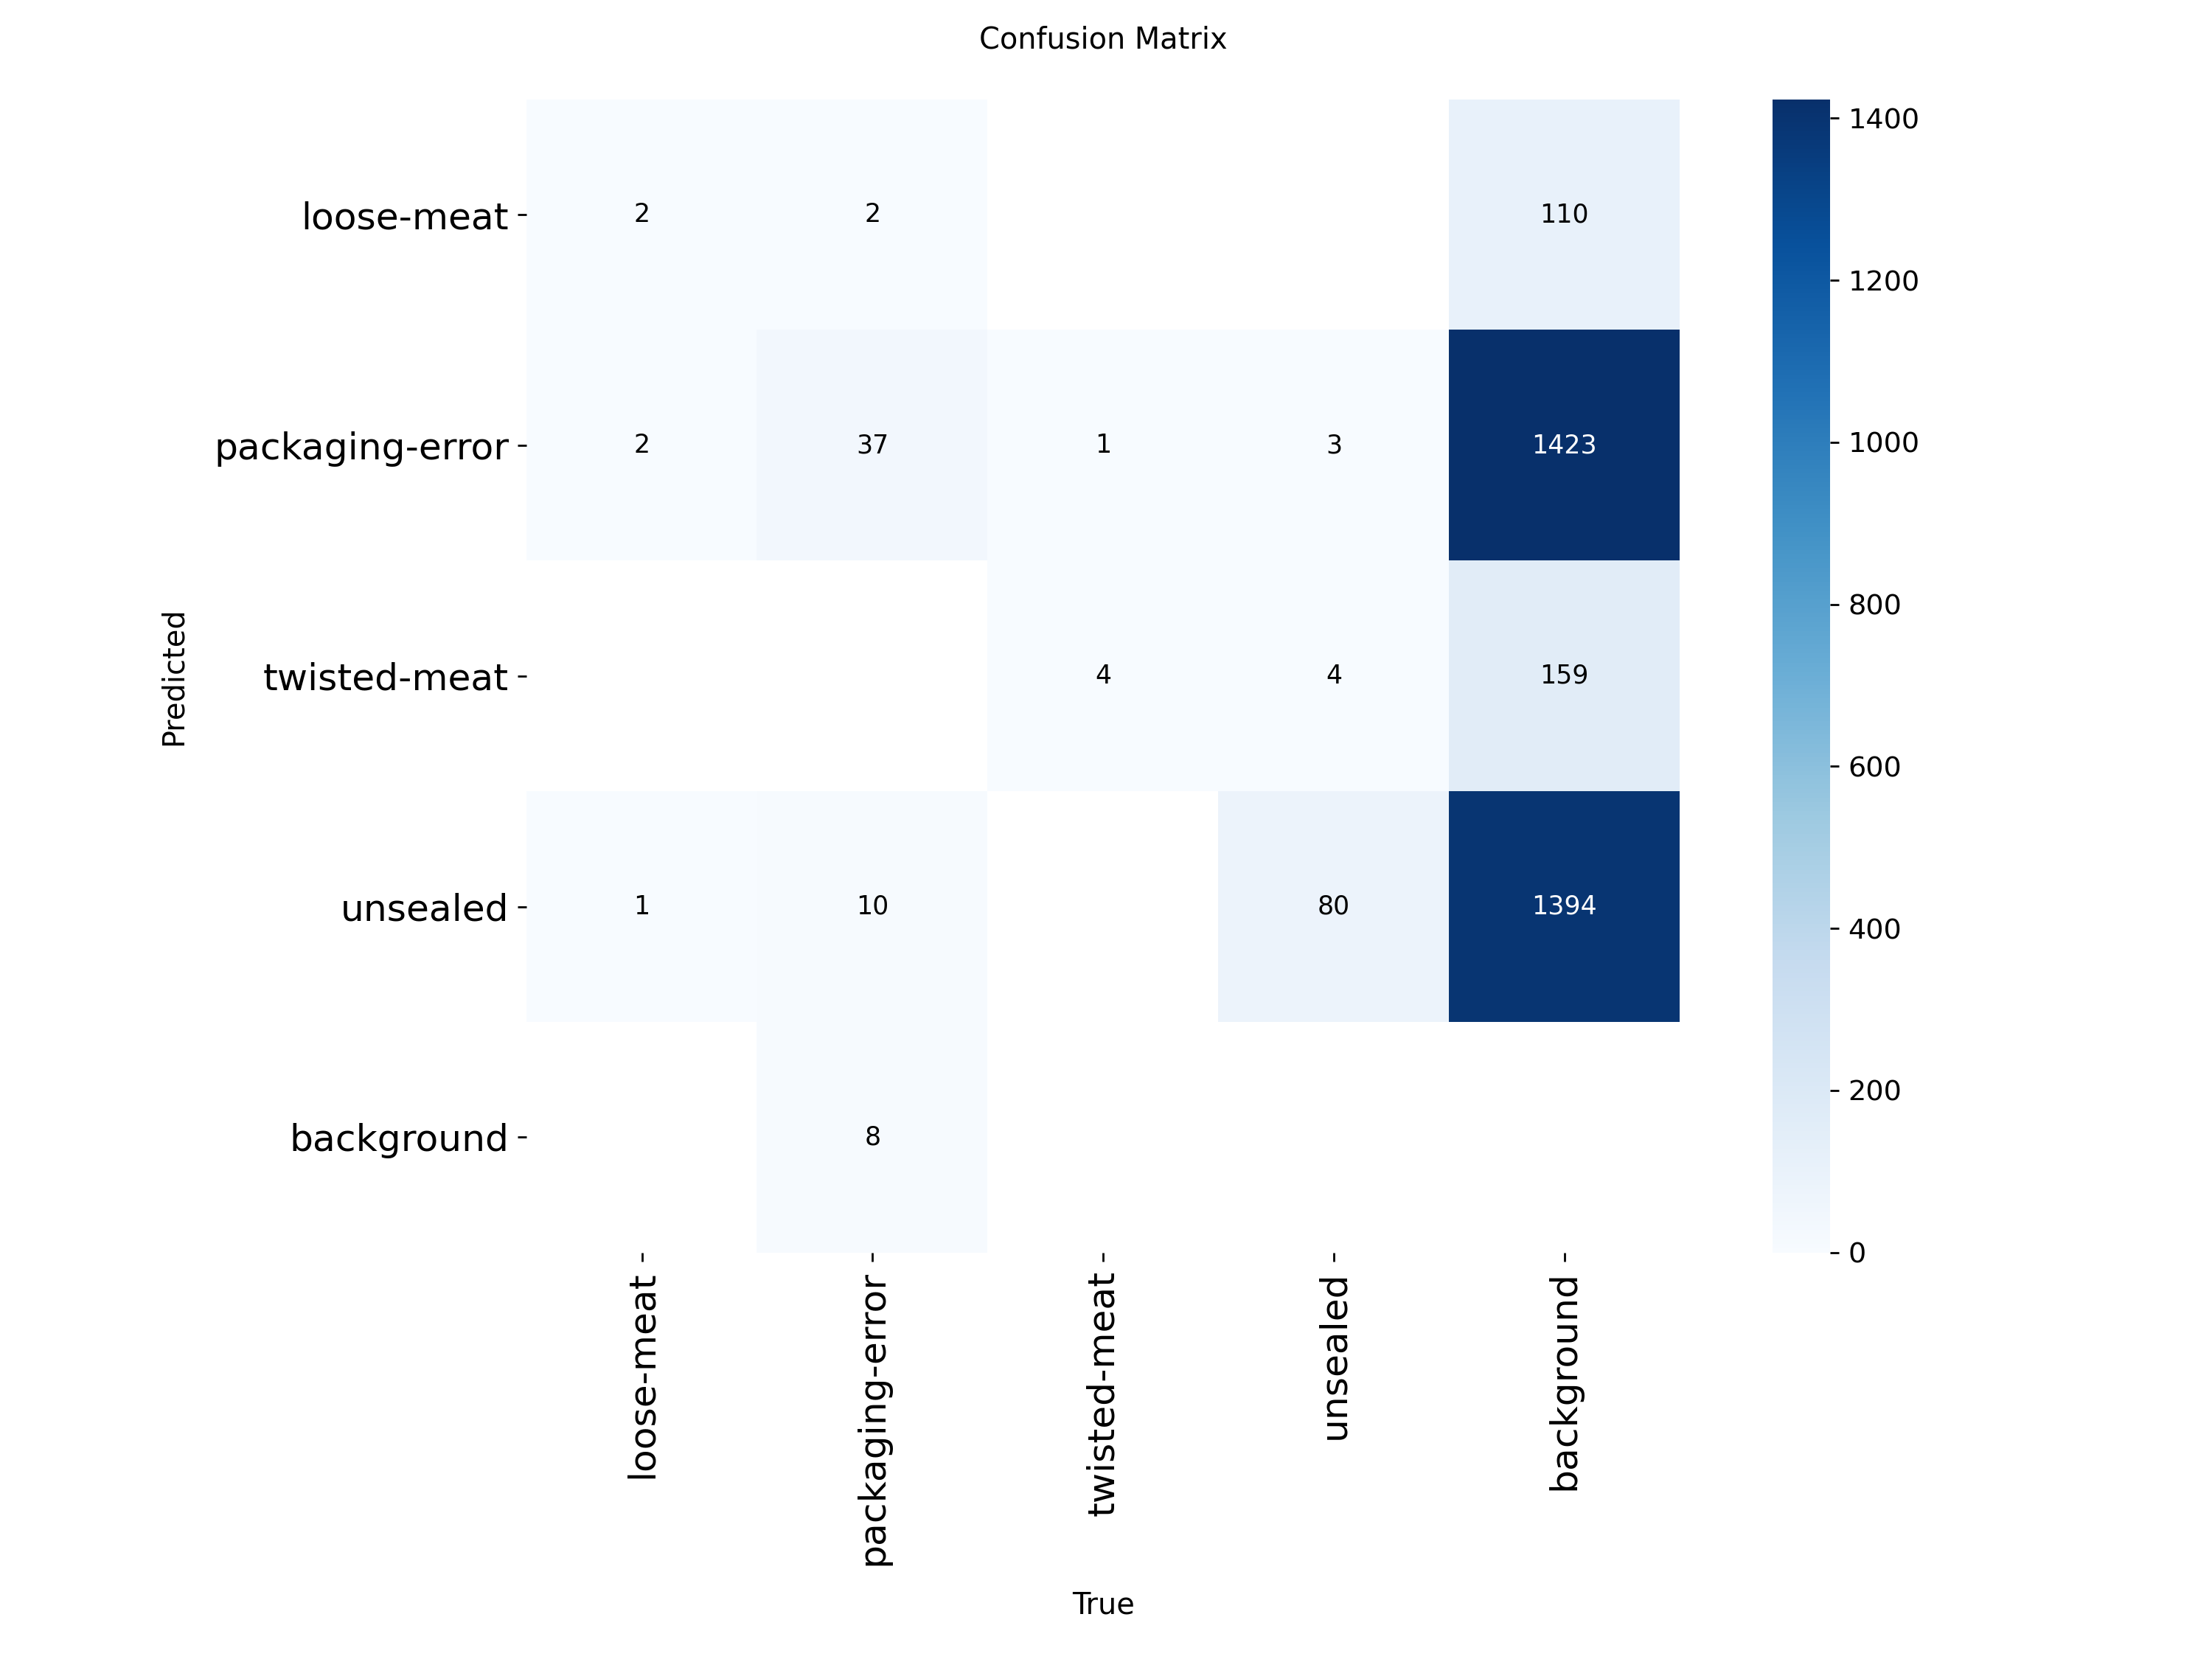

v1_no_mosaic_comparison


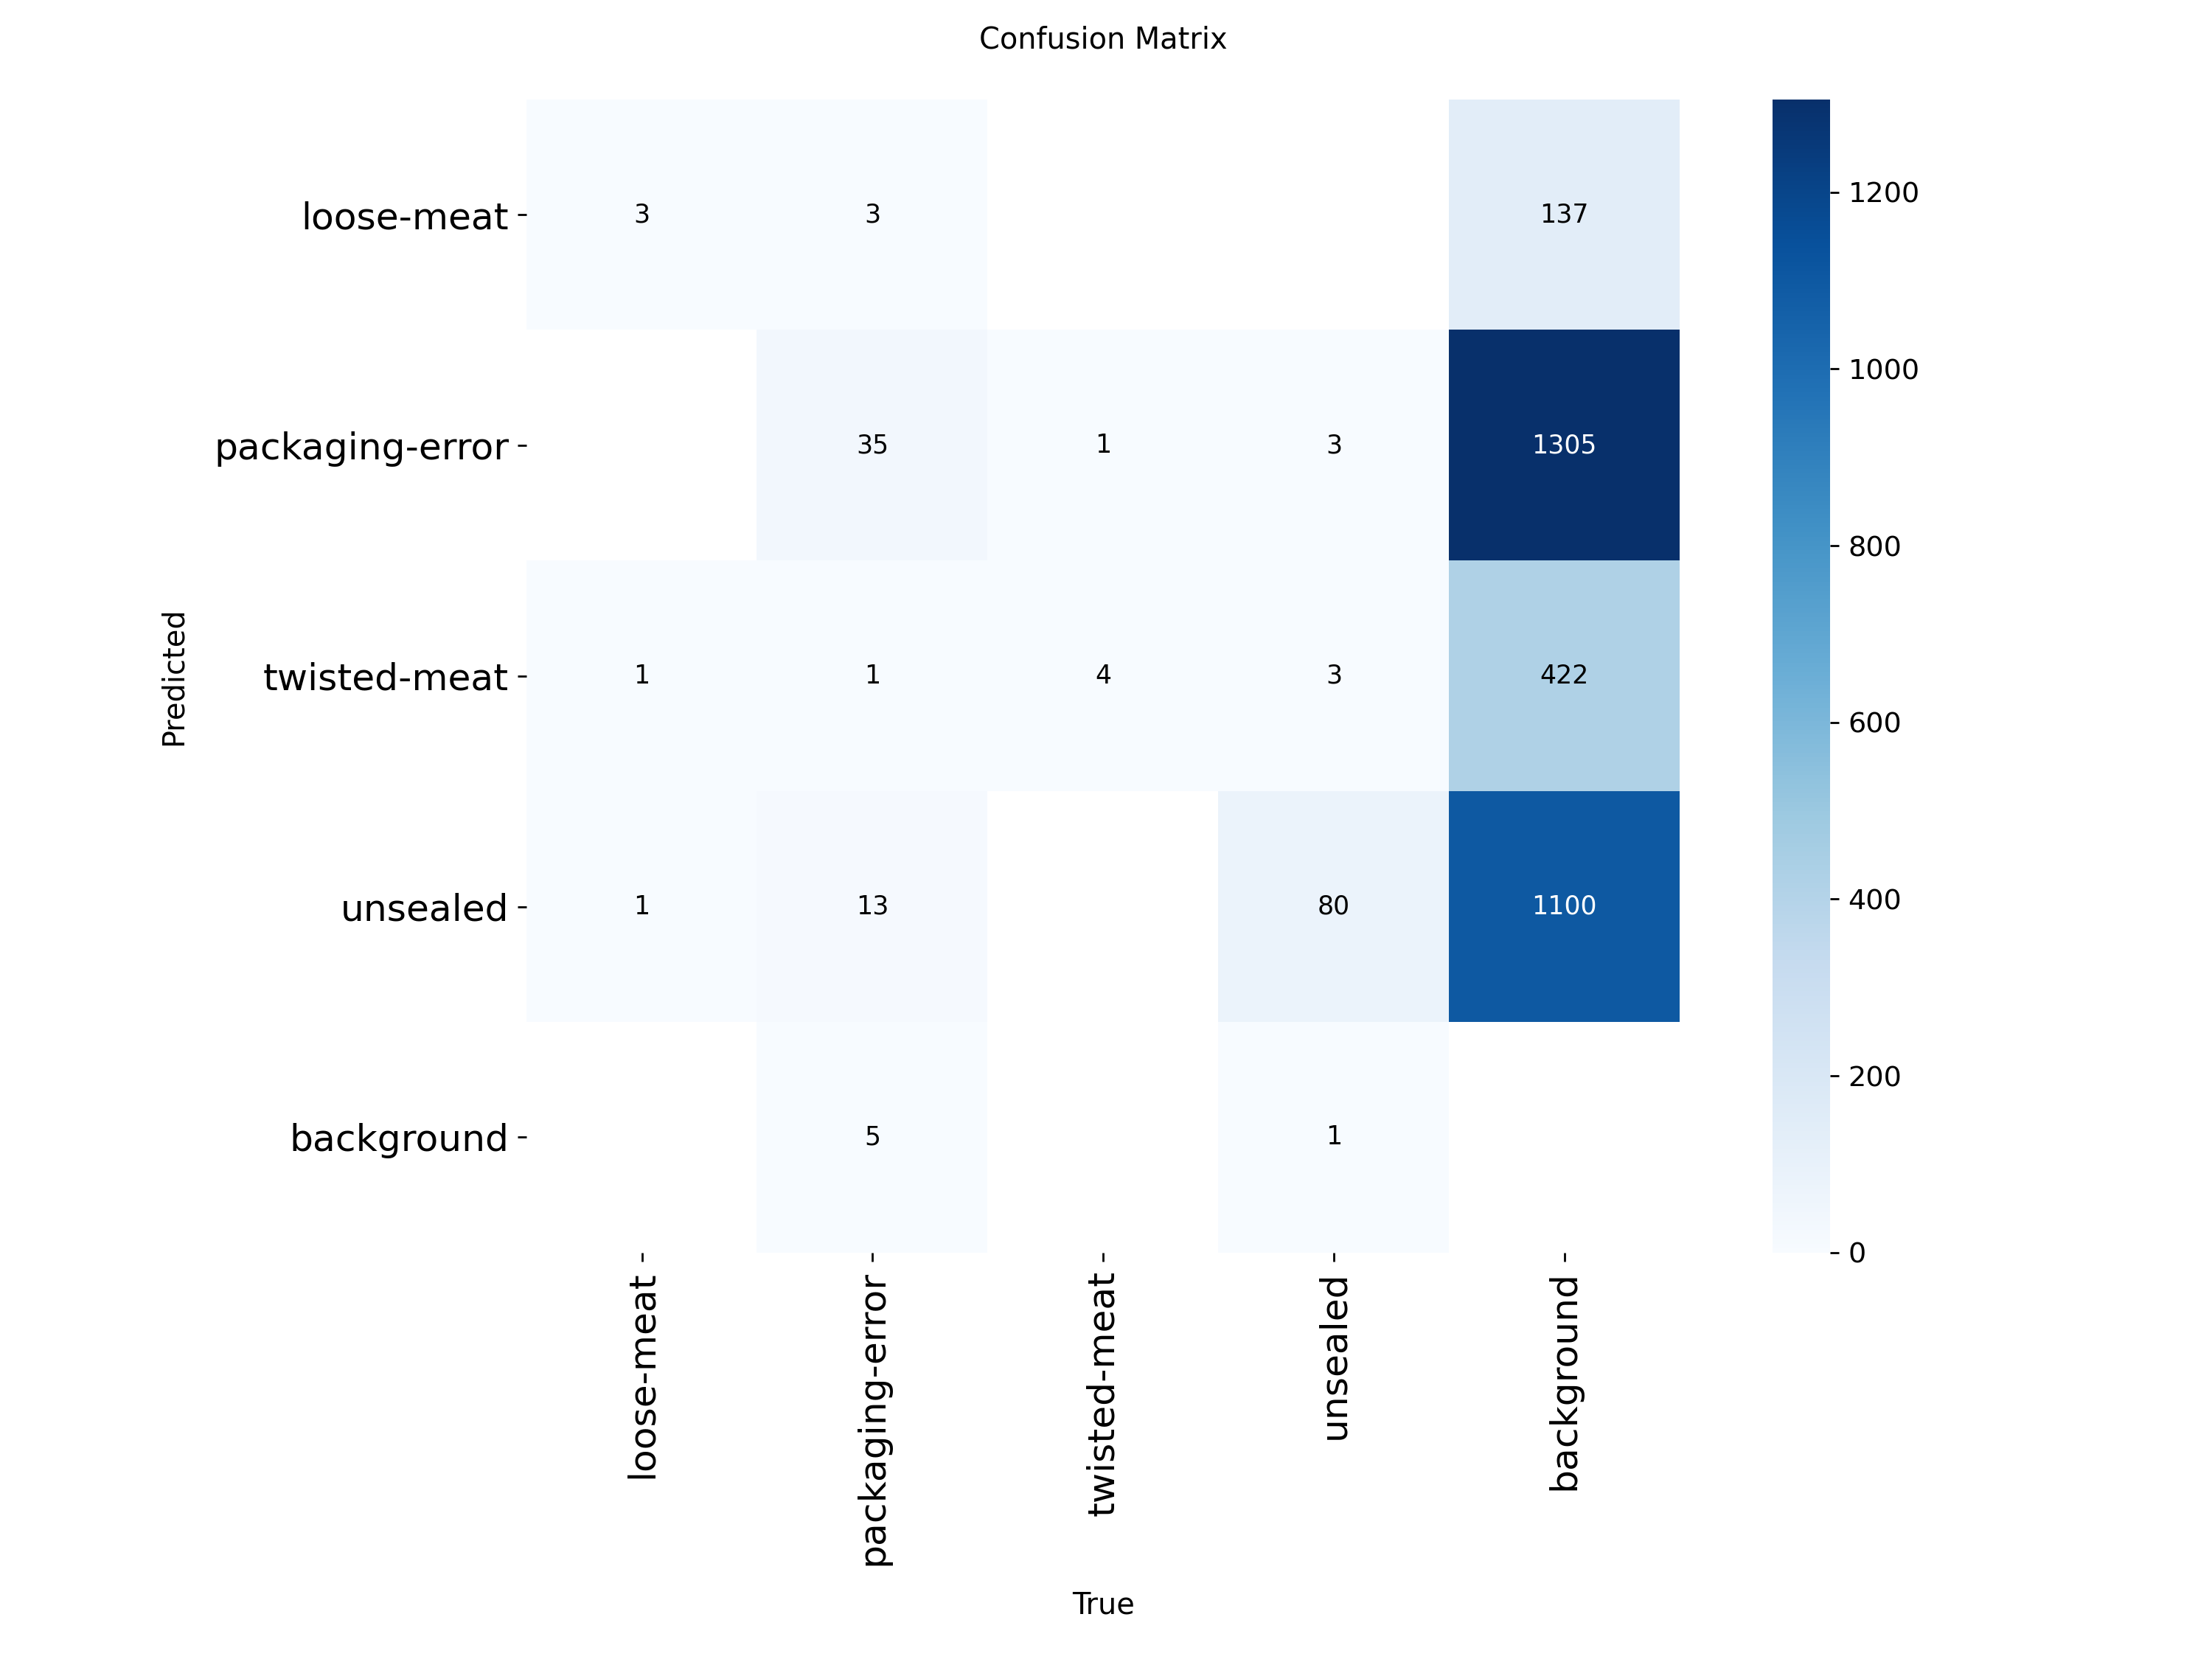

In [9]:
from PIL import Image

for name in ["v1_baseline_comparison", "v1_no_mosaic_comparison"]:
    print(name)
    display(Image.open(runs / name / "confusion_matrix.png"))

In [10]:
baseline_025 = baseline.val(
    data=str(clean / "data.yaml"),
    imgsz=640,
    split="val",
    conf=0.25,
    iou=0.7,
    plots=True,
    project=str(runs),
    name="v1_baseline_conf025",
    exist_ok=True
)

print("Baseline evaluation complete!")

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3054.0±772.8 MB/s, size: 72.7 KB)
val: Scanning /content/pork_rasher_dataset_v1_clean/valid/labels.cache... 119 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 119/119 31.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.1it/s 3.7s
                   all        119        154      0.621      0.523      0.495      0.231
            loose-meat          5          5      0.667        0.8      0.795      0.287
       packaging-error         35         57      0.568      0.277      0.215     0.0765
          twisted-meat          4          5        0.5        0.2      0.195     0.0975
              unsealed         84         87       0.75      0.816      0.774      0.464
Speed: 7.0ms preprocess, 4.9m

In [11]:
no_mosaic_025 = no_mosaic.val(
    data=str(clean / "data.yaml"),
    imgsz=640,
    split="val",
    conf=0.25,
    iou=0.7,
    plots=True,
    project=str(runs),
    name="v1_no_mosaic_conf025",
    exist_ok=True
)

print("No-mosaic evaluation complete!")

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2424.4±1057.6 MB/s, size: 72.5 KB)
val: Scanning /content/pork_rasher_dataset_v1_clean/valid/labels.cache... 119 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 119/119 33.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.1it/s 2.6s
                   all        119        154      0.764      0.498      0.484      0.226
            loose-meat          5          5        0.6        0.6      0.595      0.168
       packaging-error         35         57      0.667      0.211      0.193     0.0592
          twisted-meat          4          5          1        0.4      0.395      0.197
              unsealed         84         87      0.791      0.782      0.751       0.48
Speed: 3.7ms preprocess, 4.6

v1_baseline_conf025


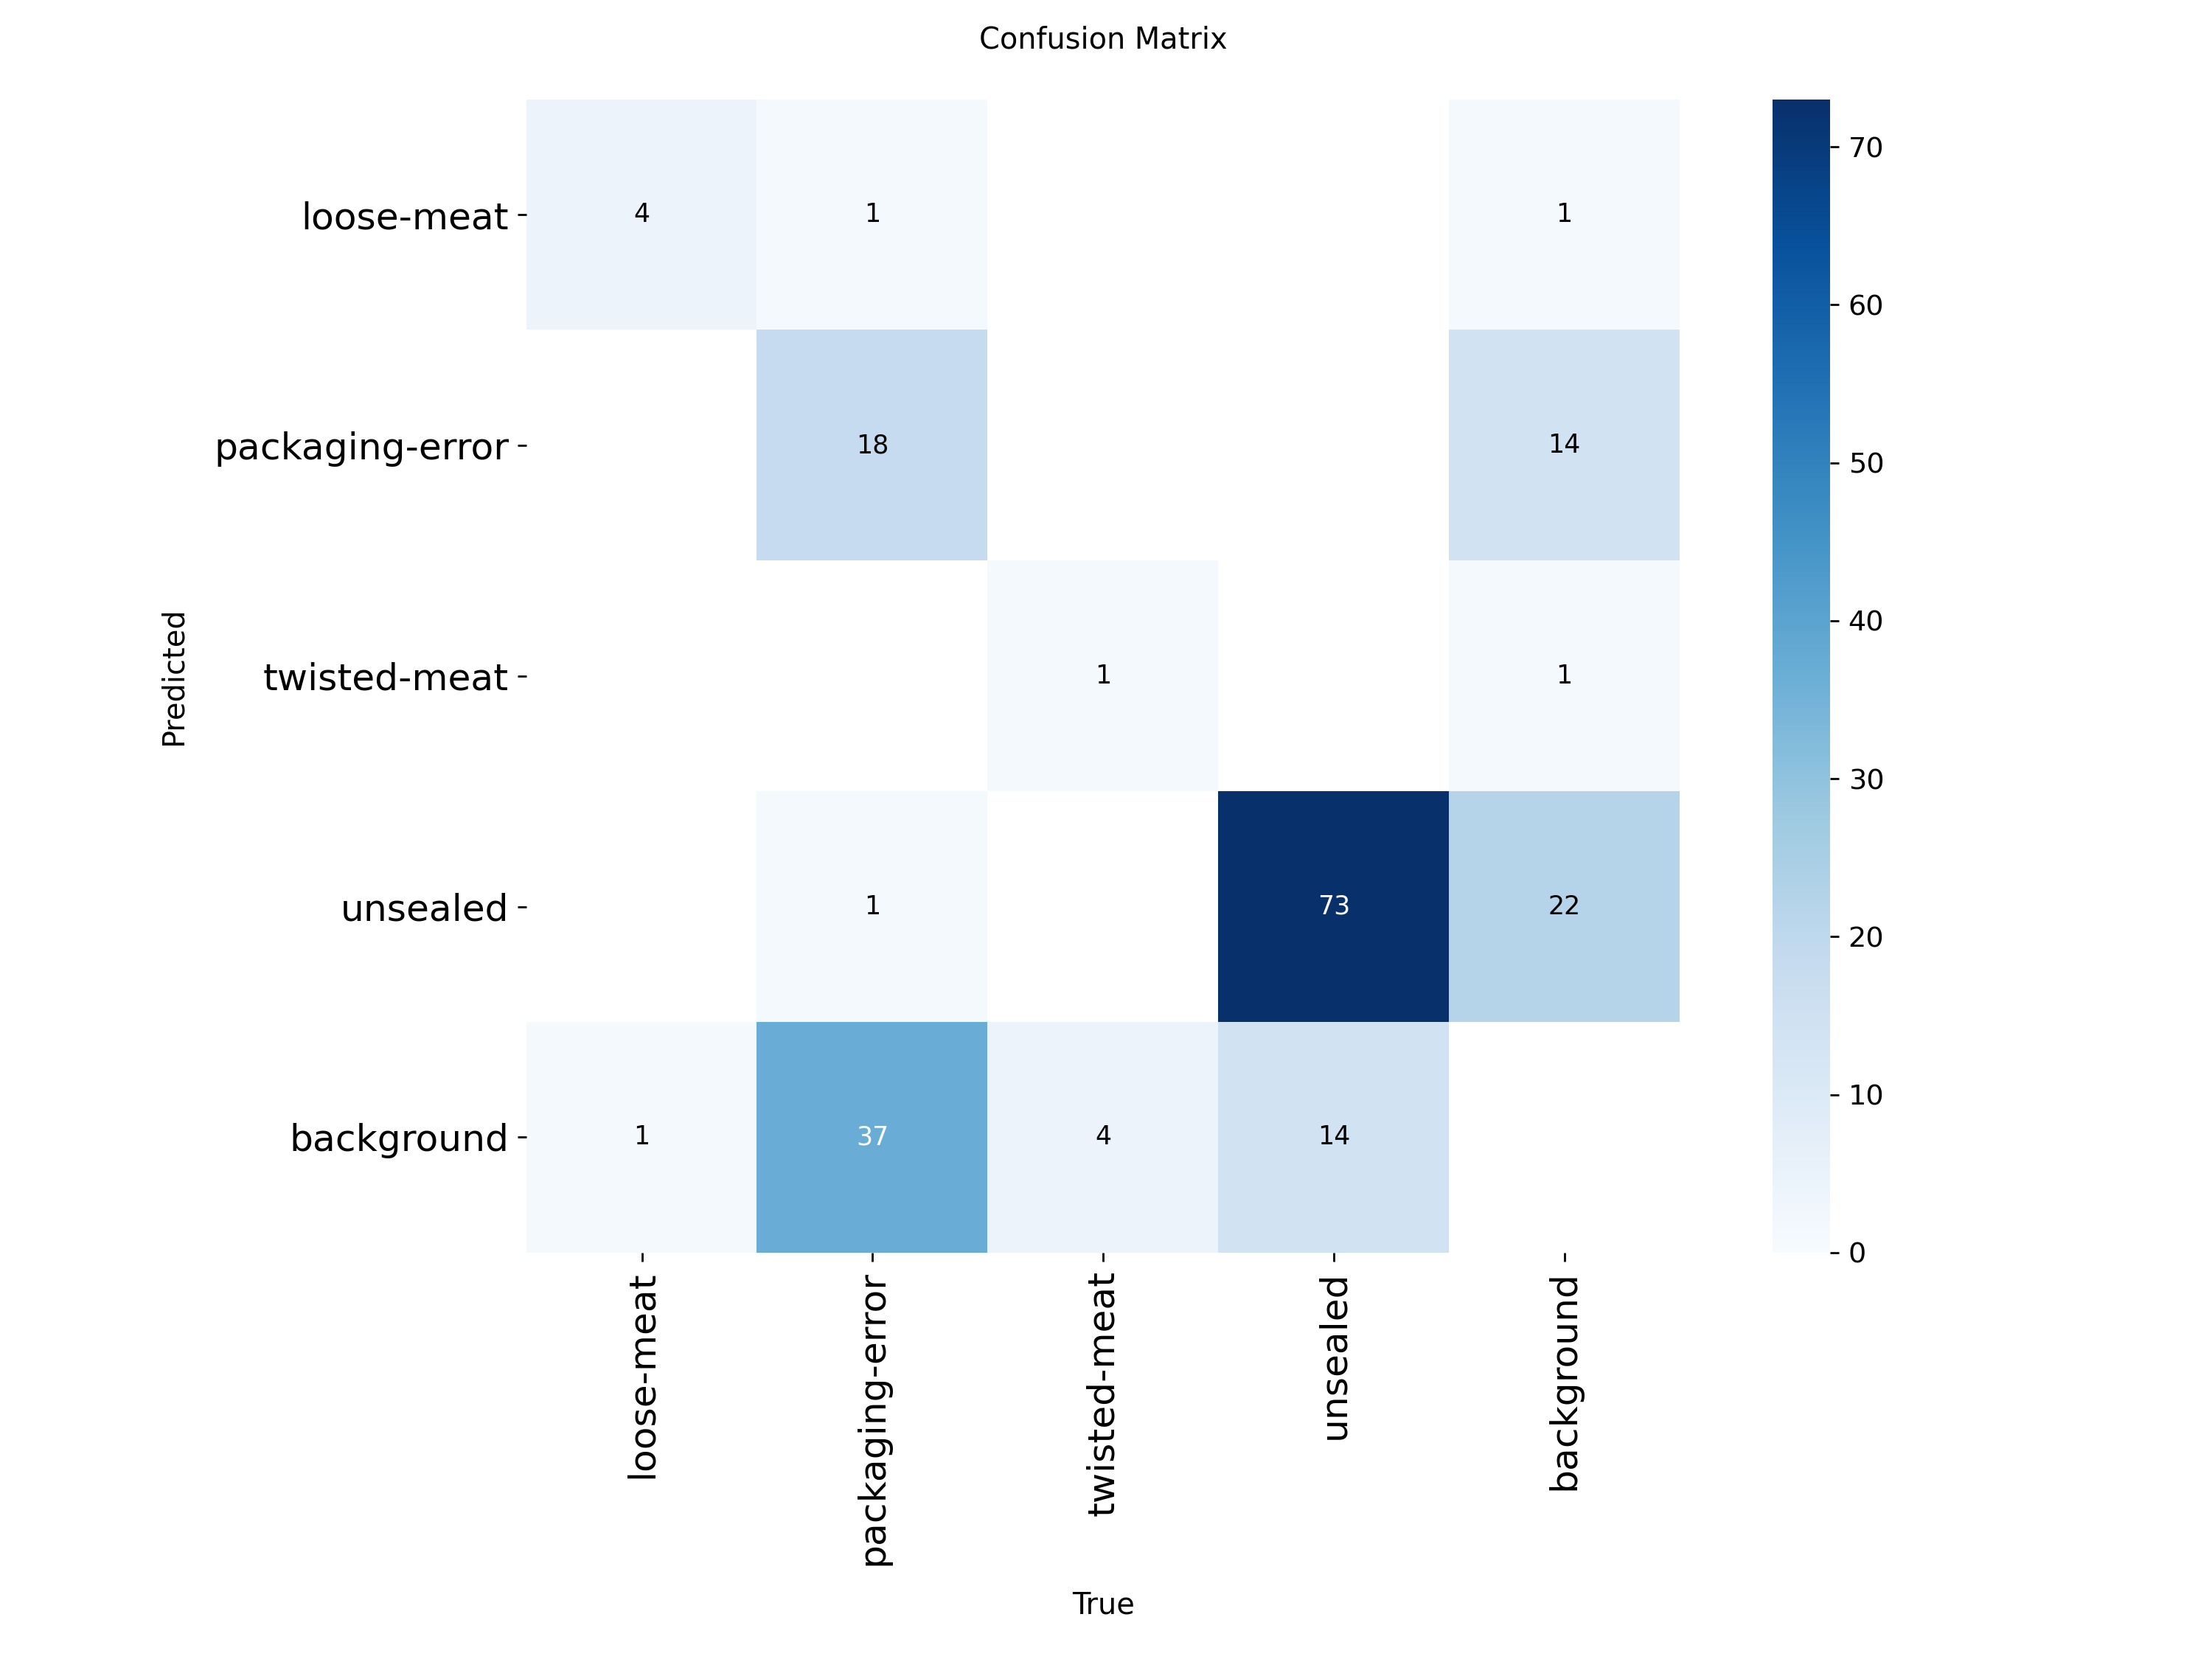

v1_no_mosaic_conf025


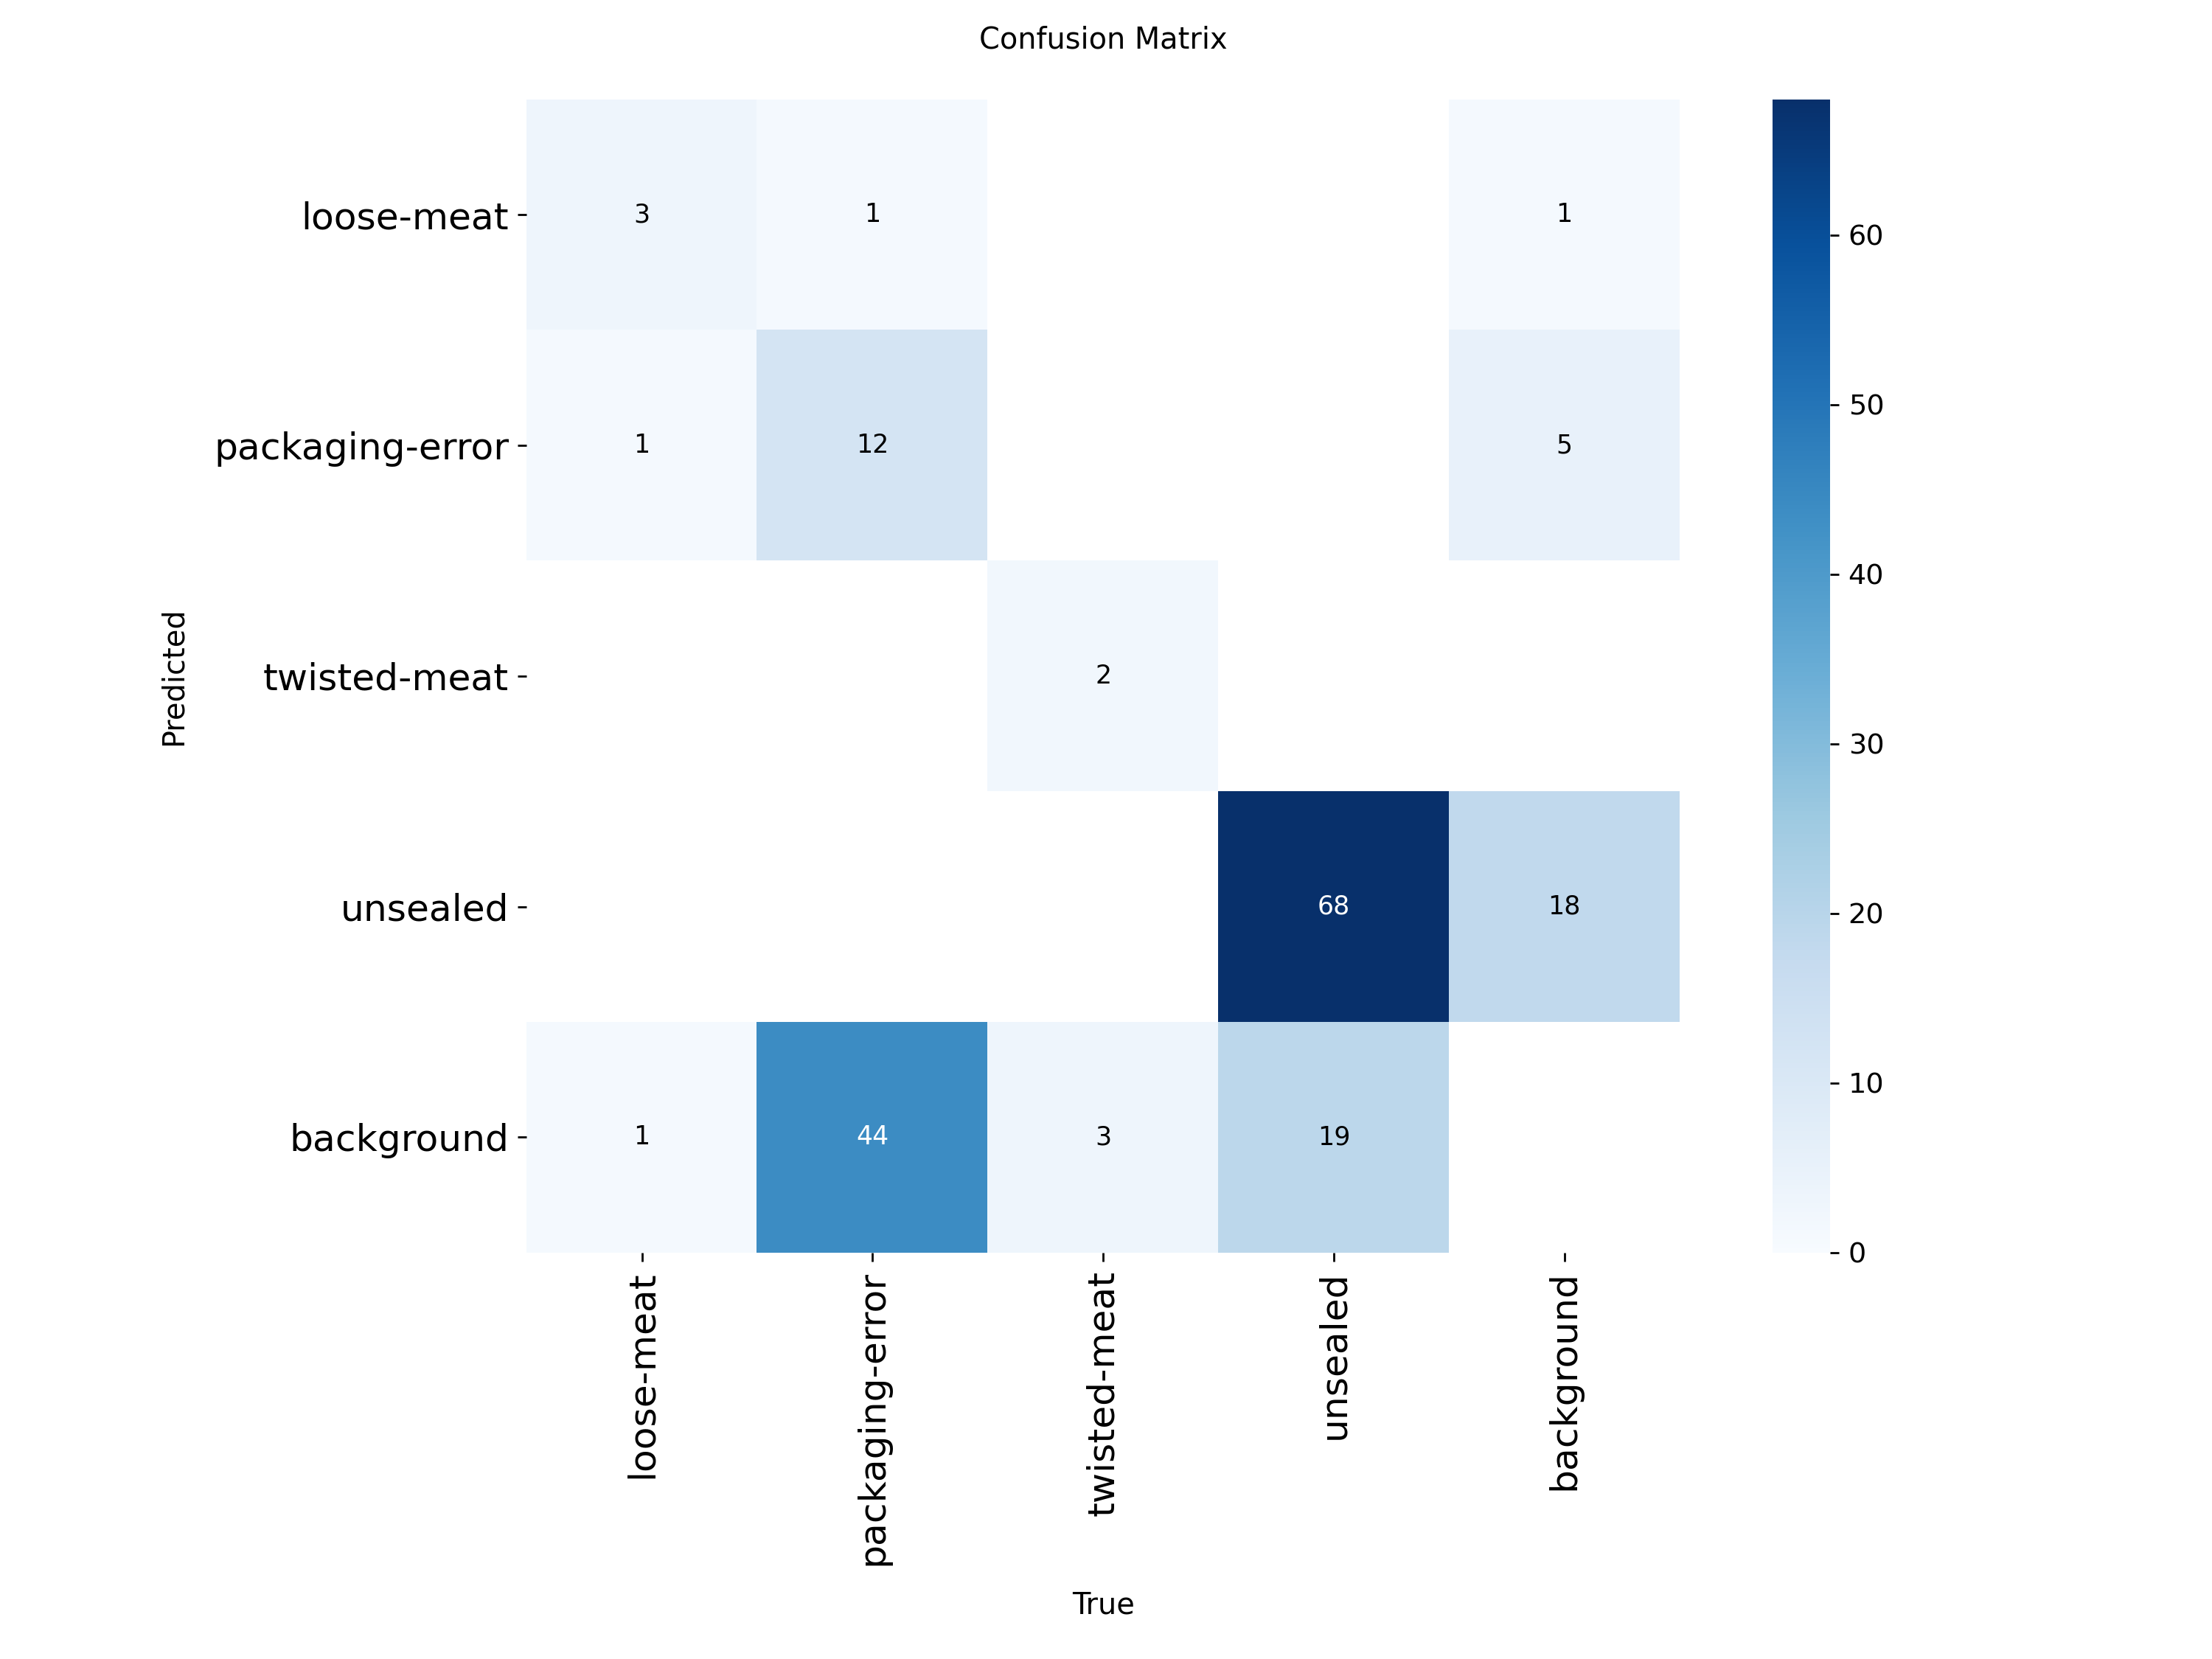

In [12]:
from PIL import Image

for name in ["v1_baseline_conf025", "v1_no_mosaic_conf025"]:
    print(name)
    display(Image.open(runs / name / "confusion_matrix.png"))

v1_baseline_comparison


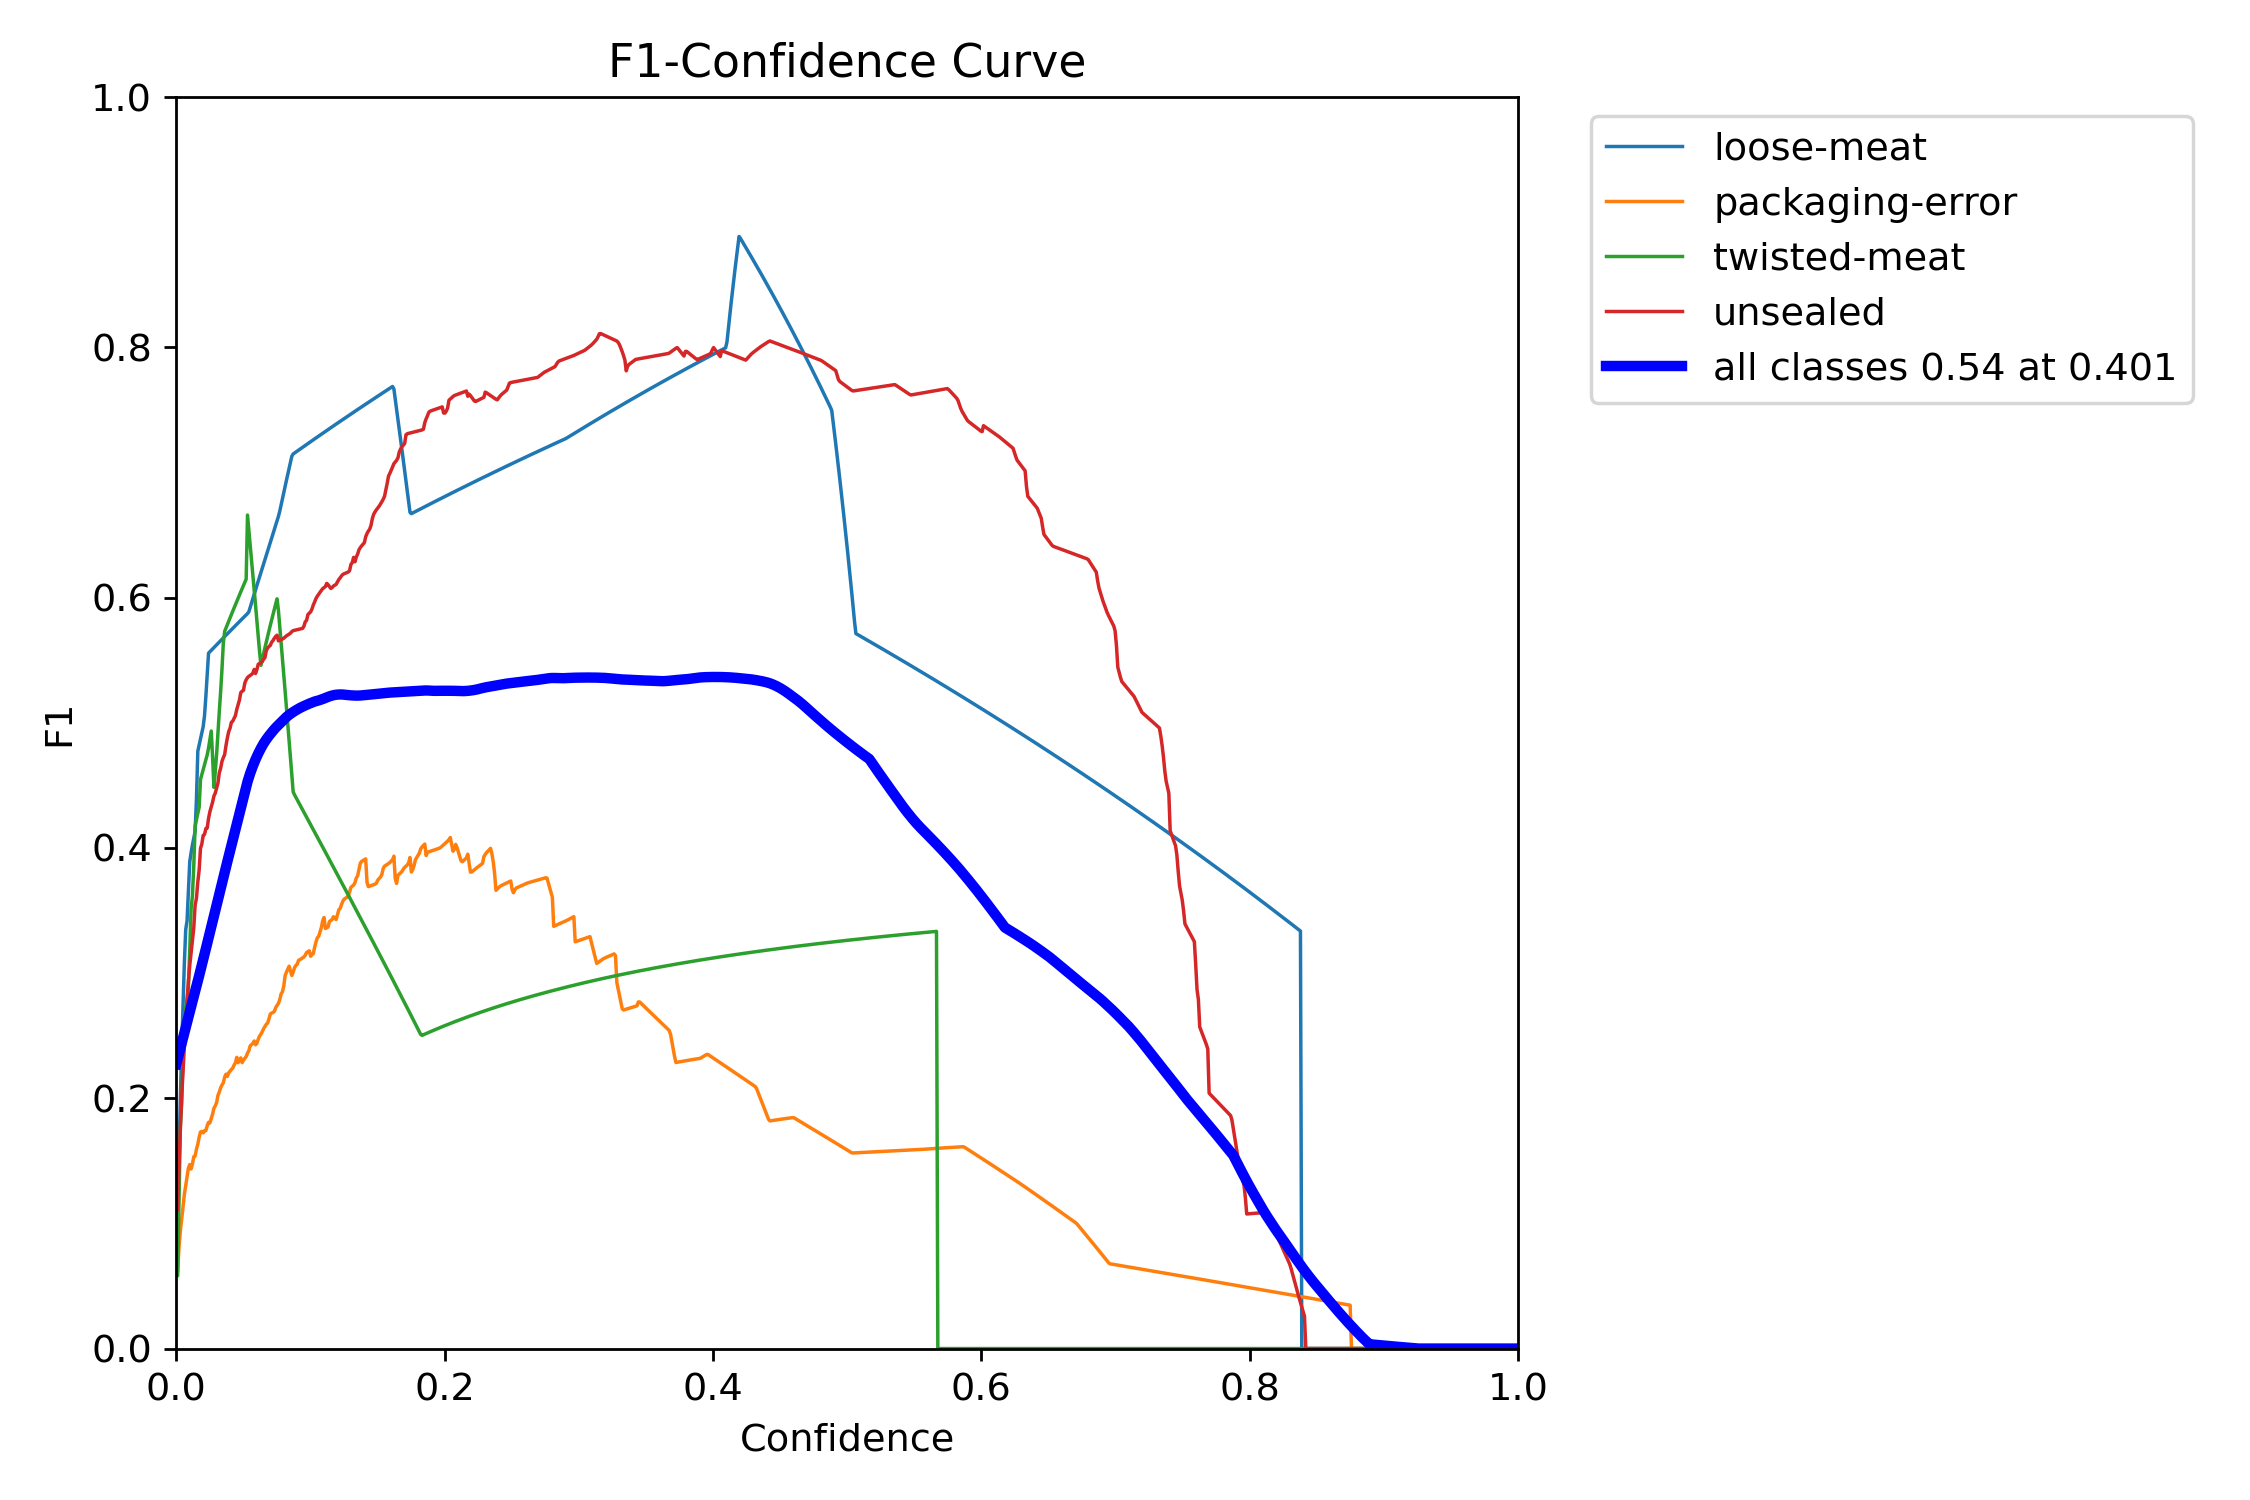

v1_no_mosaic_comparison


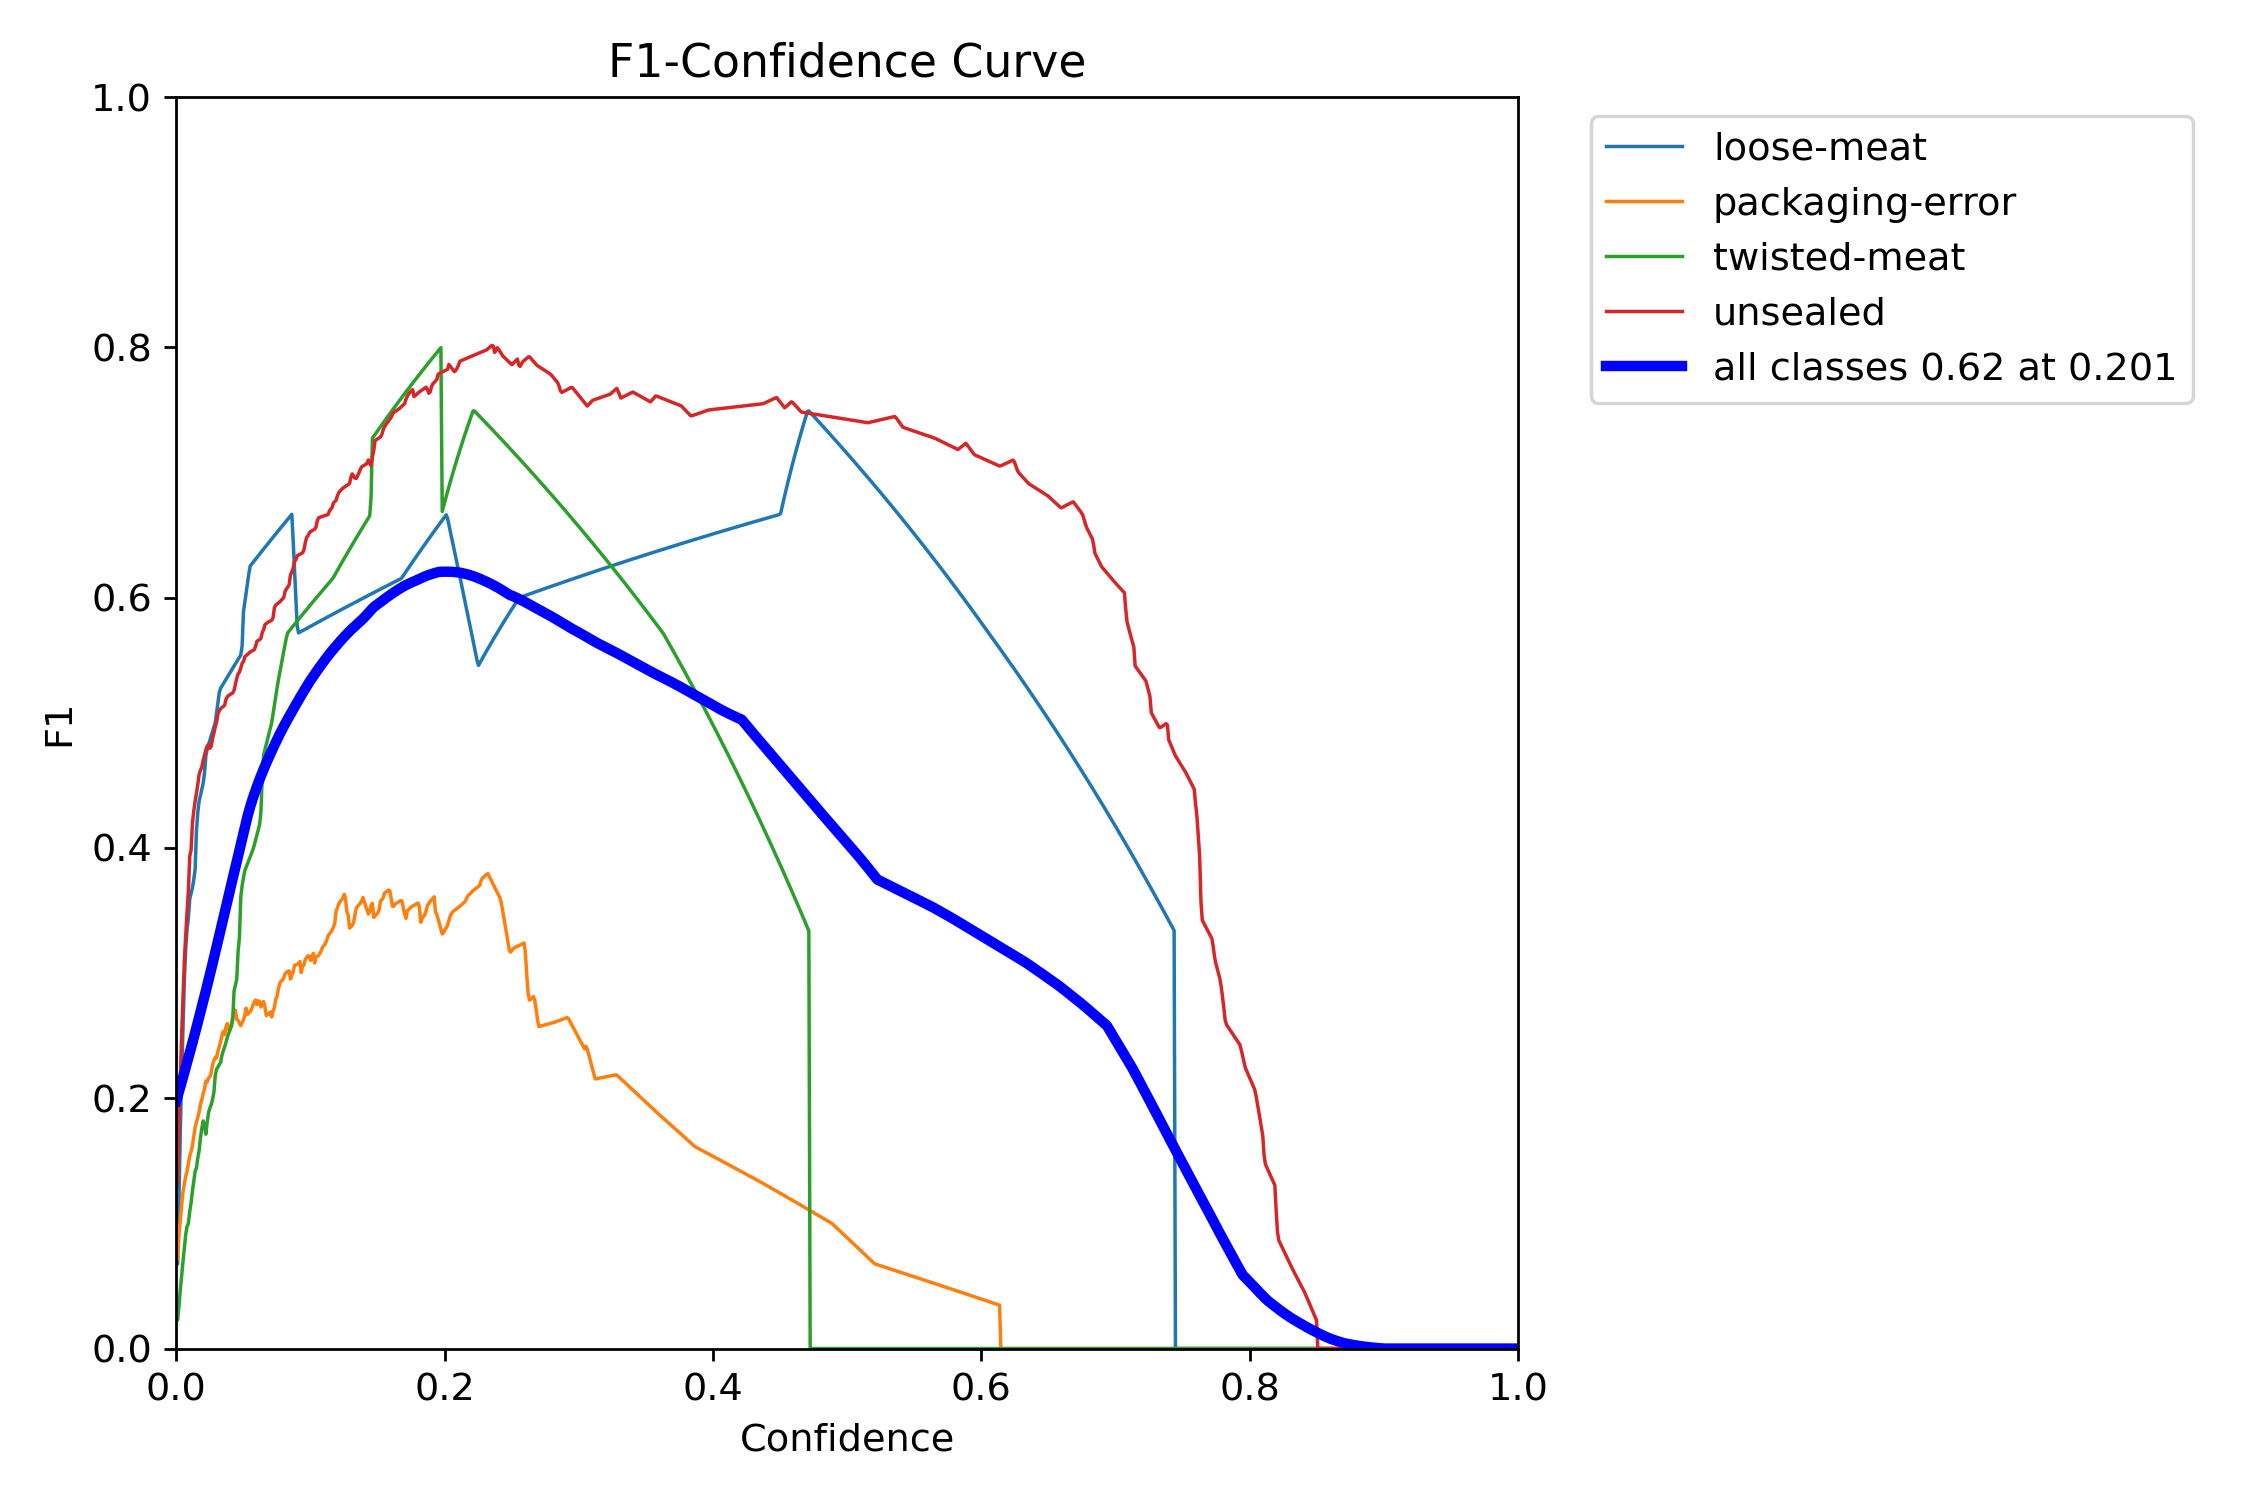

In [13]:
# Display F1-confidence curves
from PIL import Image

for name in ["v1_baseline_comparison", "v1_no_mosaic_comparison"]:
    print(name)
    display(Image.open(runs / name / "BoxF1_curve.png"))

In [14]:
# Evaluate both models at their peak-F1 confidence
models = {
    "baseline": (baseline, 0.401),
    "no_mosaic": (no_mosaic, 0.201)
}

for name, (model, conf) in models.items():
    print(f"\nEvaluating {name} at confidence {conf}")

    result = model.val(
        data=str(clean / "data.yaml"),
        imgsz=640,
        split="val",
        conf=conf,
        iou=0.7,
        plots=True,
        project=str(runs),
        name=f"v1_{name}_peak_f1",
        exist_ok=True
    )


Evaluating baseline at confidence 0.401
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2838.5±706.3 MB/s, size: 74.2 KB)
val: Scanning /content/pork_rasher_dataset_v1_clean/valid/labels.cache... 119 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 119/119 22.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.5it/s 3.2s
                   all        119        154      0.847      0.462      0.451      0.217
            loose-meat          5          5        0.8        0.8      0.795      0.287
       packaging-error         35         57        0.7      0.123      0.114     0.0503
          twisted-meat          4          5          1        0.2      0.195     0.0975
              unsealed         84         87      0.887      0.724        0.7

v1_baseline_peak_f1


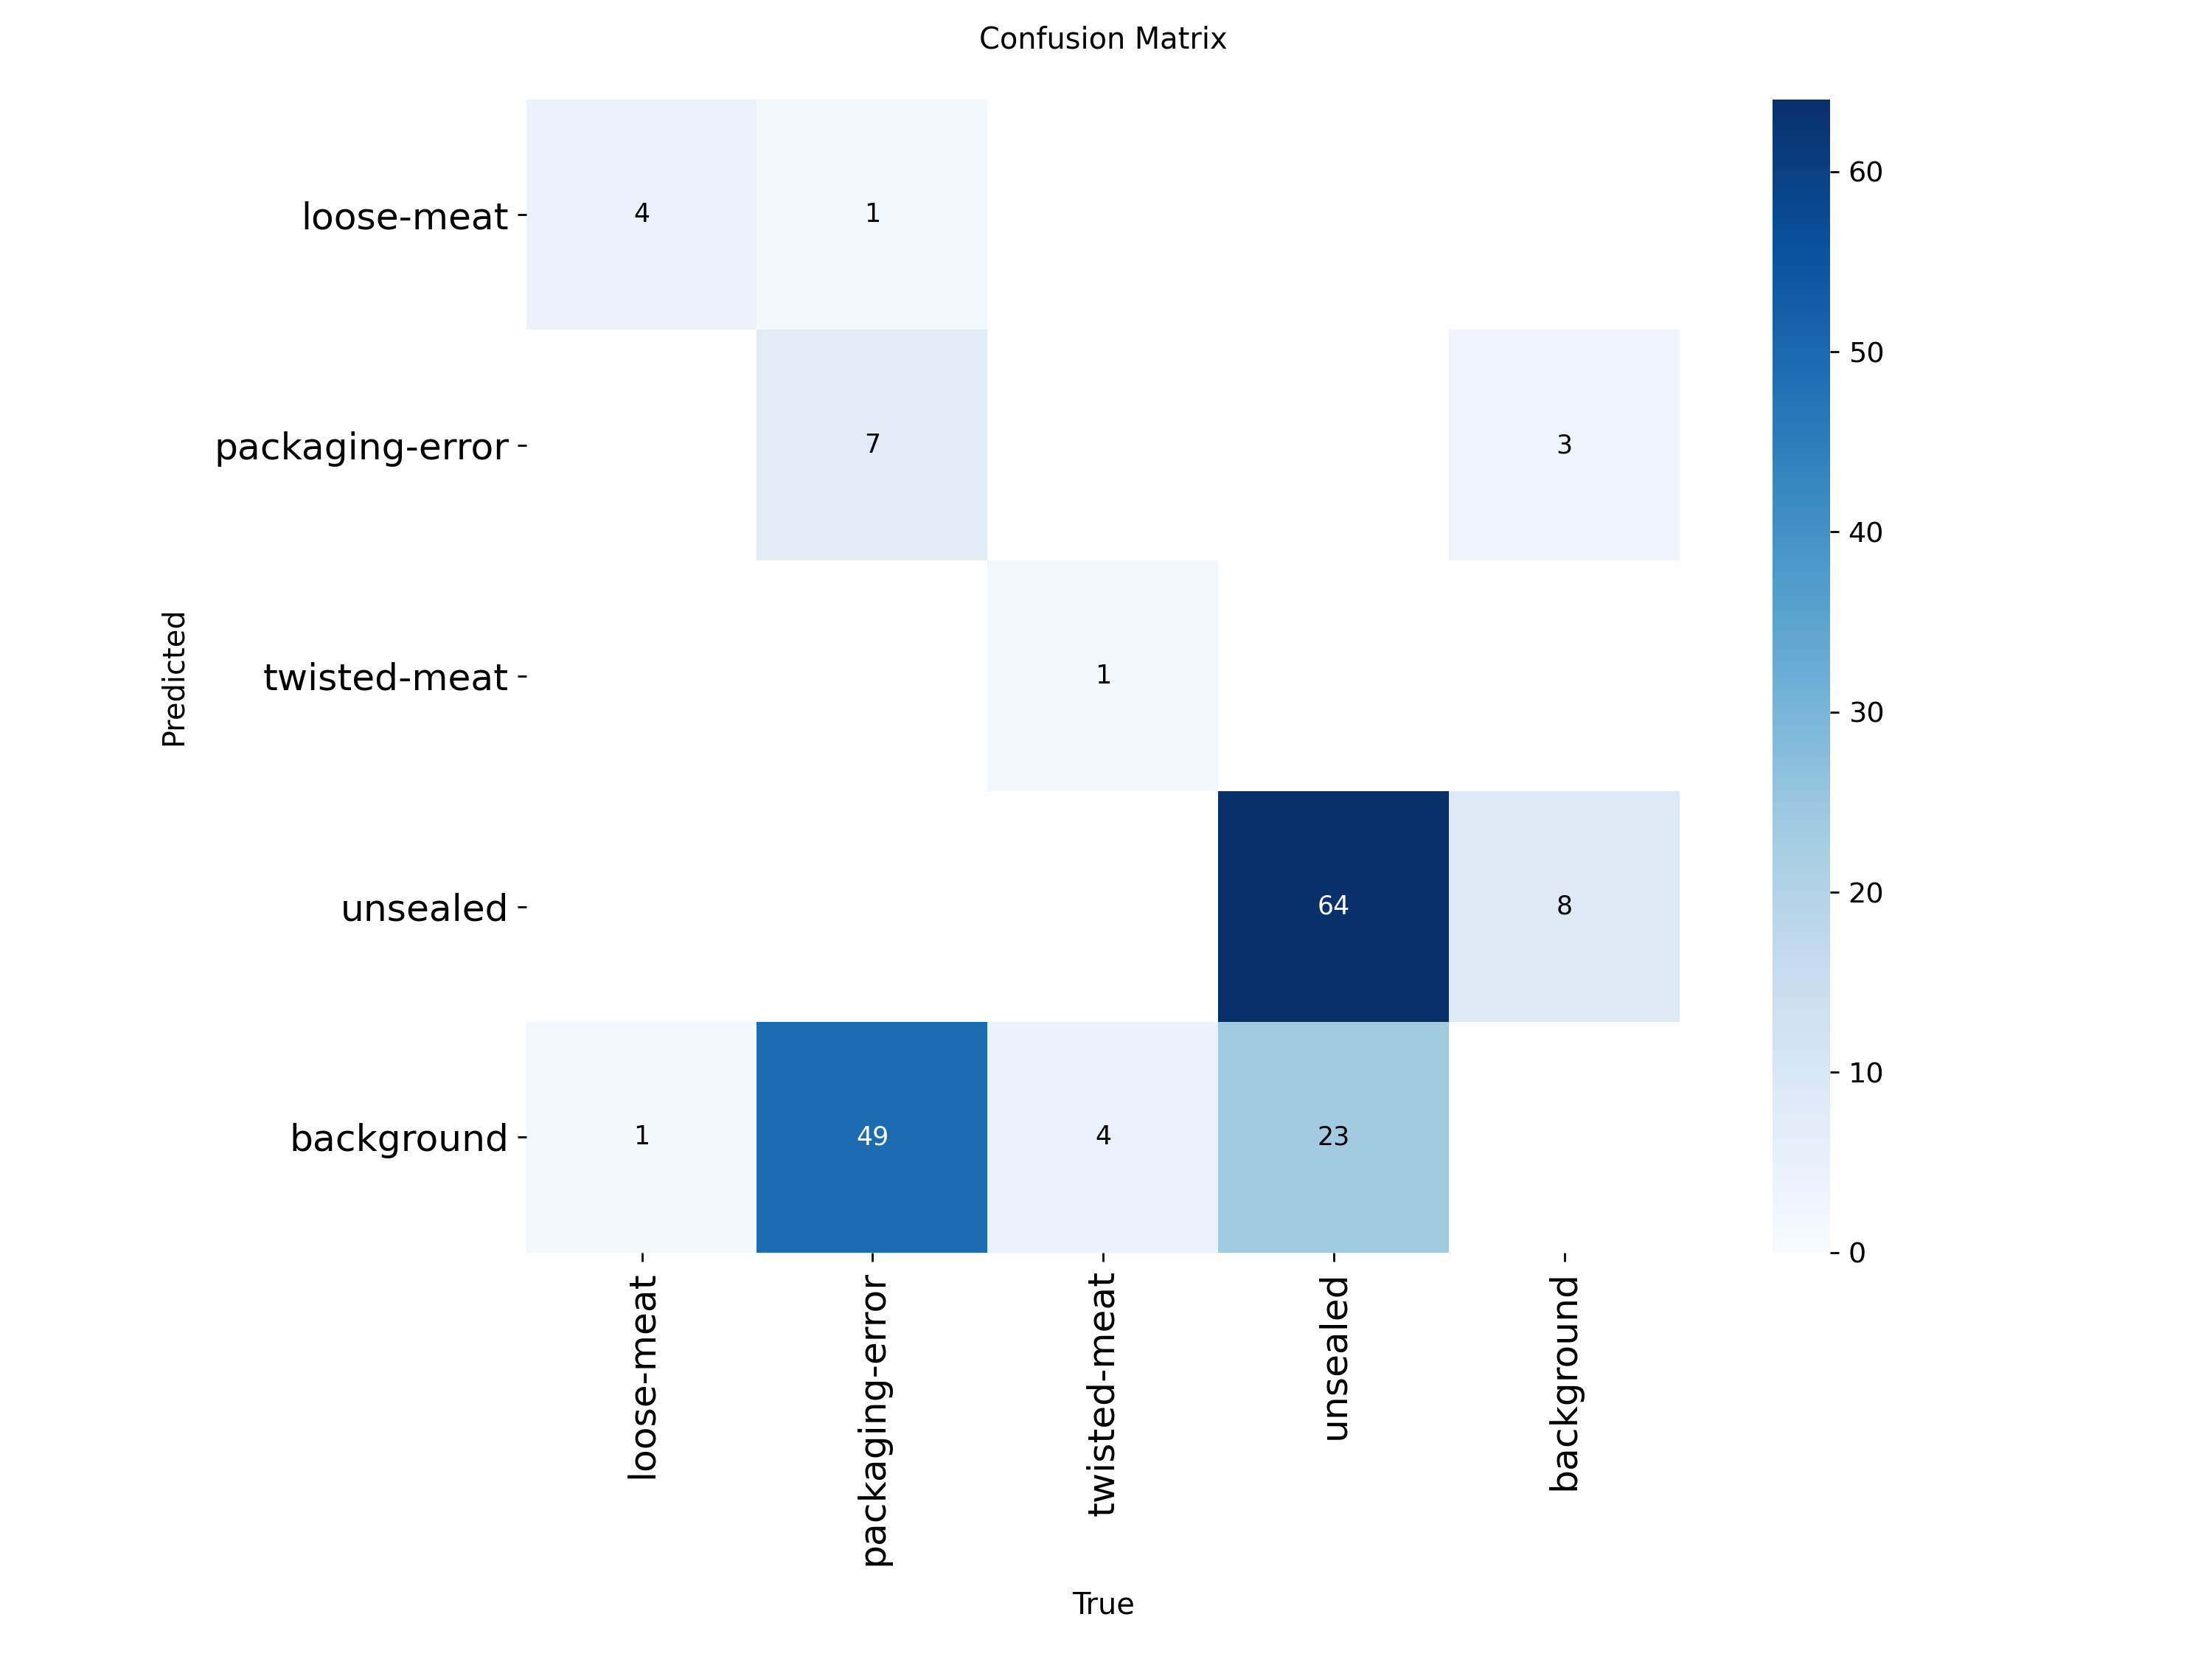

v1_no_mosaic_peak_f1


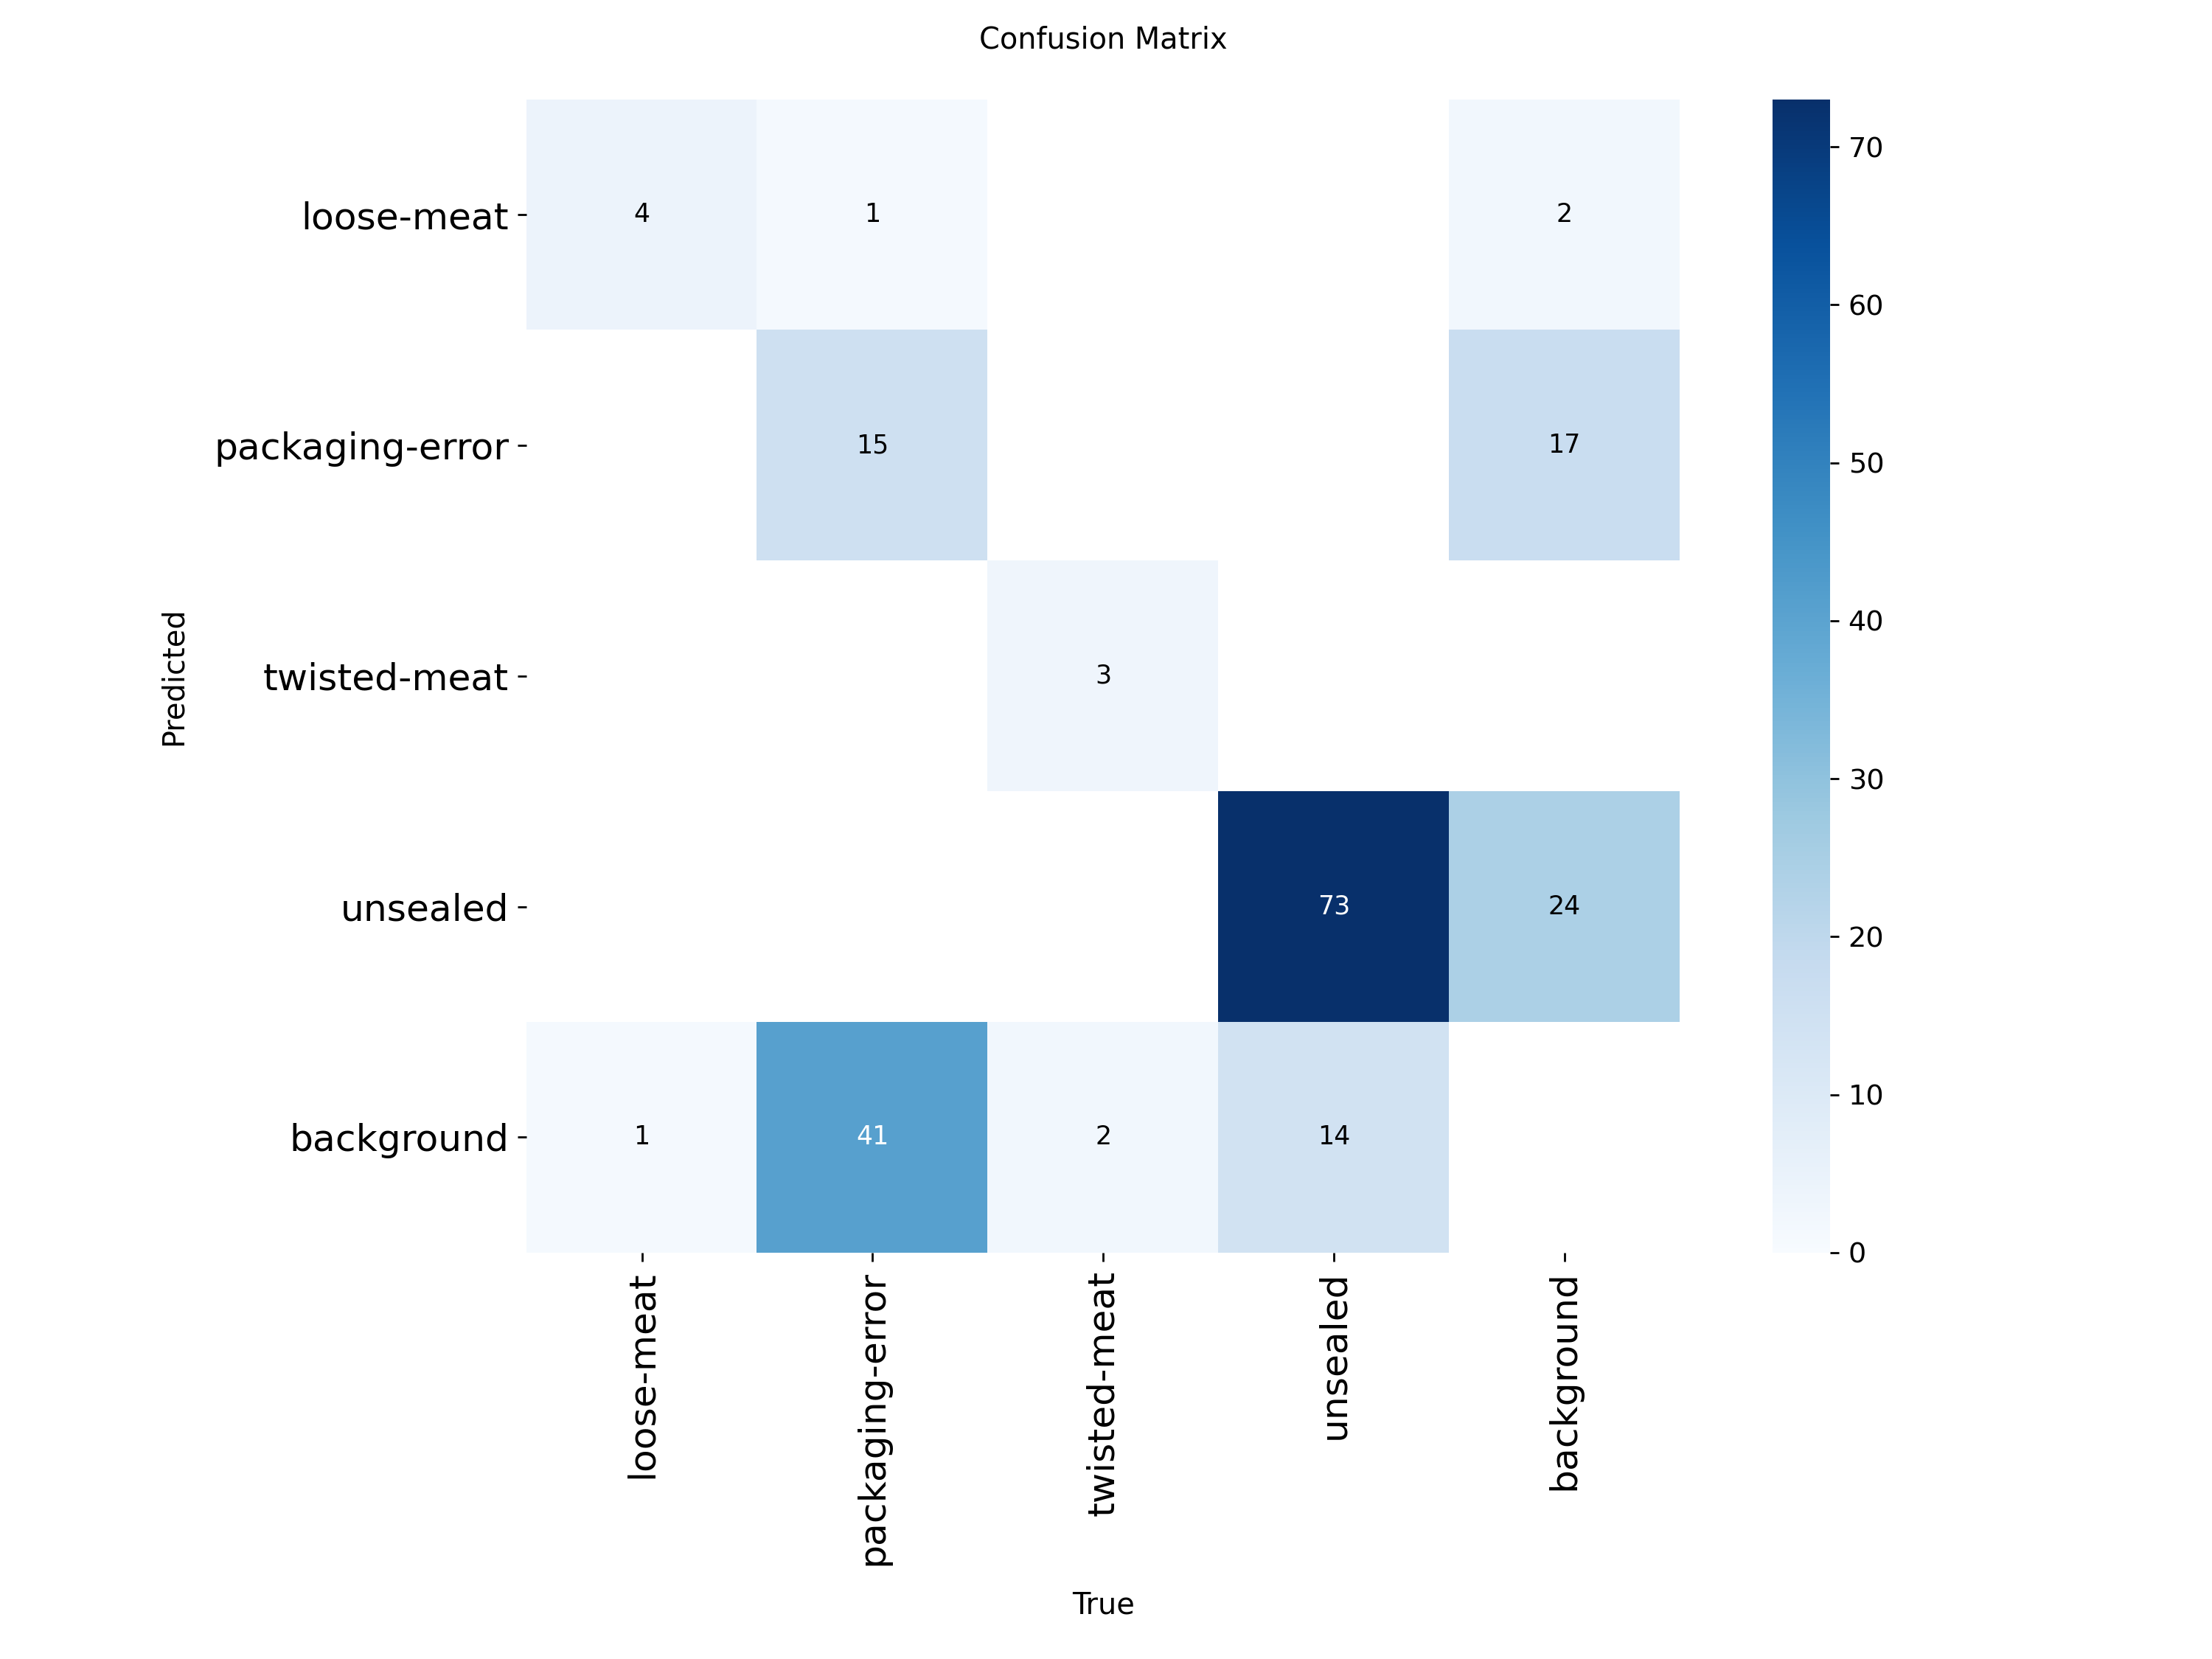

In [15]:
from PIL import Image

for name in ["v1_baseline_peak_f1", "v1_no_mosaic_peak_f1"]:
    print(name)
    display(Image.open(runs / name / "confusion_matrix.png"))

## Packaging-Error Examples
The following images contain a labelled packaging error but no packaging-error prediction at confidence 0.201. This is an image-level check, not a box-matching calculation of false negatives.

In [16]:
# Find labelled packaging-error images with no packaging-error predictions.
val_images = clean / "valid/images"
val_labels = clean / "valid/labels"

no_class_predictions = []

for label in val_labels.glob("*.txt"):
    classes = [int(line.split()[0]) for line in label.read_text().splitlines()]

    if 1 not in classes:
        continue

    image = val_images / f"{label.stem}.jpg"
    result = no_mosaic.predict(str(image), conf=0.201, verbose=False)[0]

    if 1 not in result.boxes.cls.tolist():
        no_class_predictions.append(image)

print("Images with no packaging-error predictions:", len(no_class_predictions))
print("First five:", [p.name for p in no_class_predictions[:5]])

Images with no packaging-error predictions: 18
First five: ['frame_with_red_1456_jpg.rf.dea60a2ee142832fbebe0ed93f1e590b.jpg', 'frame_with_red_7317_jpg.rf.b98985ffa70d03c6e7d08839061a1c96.jpg', 'frame_with_red_6238_jpg.rf.dabe78c6e67779022f5456b0f8f5258e.jpg', 'frame_with_red_36_jpg.rf.b2bf1845c134c52245c9f1a0b0c3d2b2.jpg', 'frame_with_red_4925_jpg.rf.a30a23a16f1499f590da133f4241dcfc.jpg']


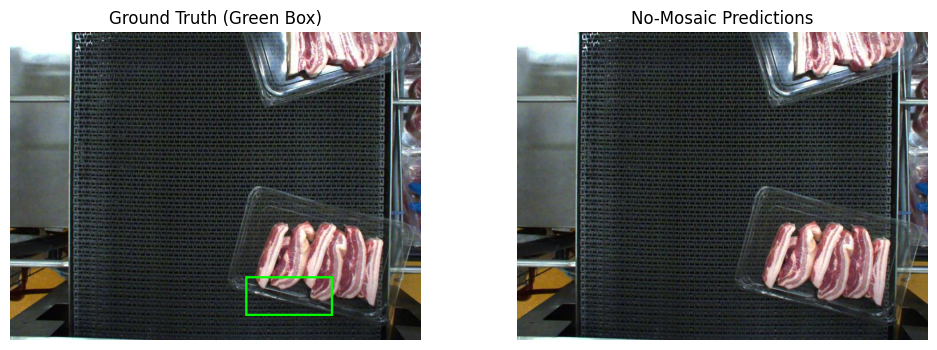

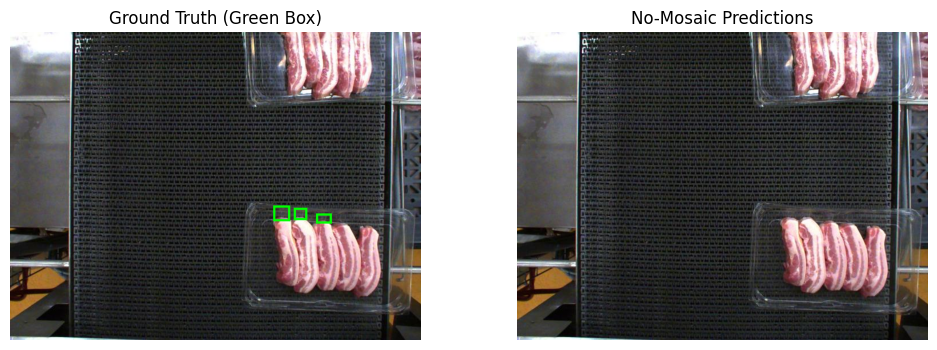

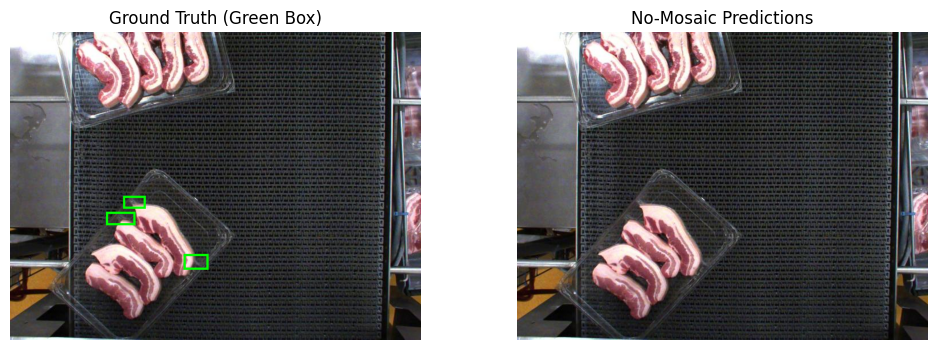

In [17]:
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

for image_path in no_class_predictions[:3]:
    image = Image.open(image_path).convert("RGB")
    ground_truth = image.copy()
    draw = ImageDraw.Draw(ground_truth)
    W, H = image.size

    # Draw actual packaging-error boxes
    label = val_labels / f"{image_path.stem}.txt"

    for line in label.read_text().splitlines():
        cls, x, y, w, h = map(float, line.split())

        if int(cls) == 1:
            box = [(x-w/2)*W, (y-h/2)*H, (x+w/2)*W, (y+h/2)*H]
            draw.rectangle(box, outline="lime", width=4)

    # Model predictions
    result = no_mosaic.predict(str(image_path), conf=0.201, imgsz=640, verbose=False)[0]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].imshow(ground_truth)
    axes[0].set_title("Ground Truth (Green Box)")
    axes[1].imshow(result.plot()[:, :, ::-1])
    axes[1].set_title("No-Mosaic Predictions")

    for ax in axes:
        ax.axis("off")

    plt.show()

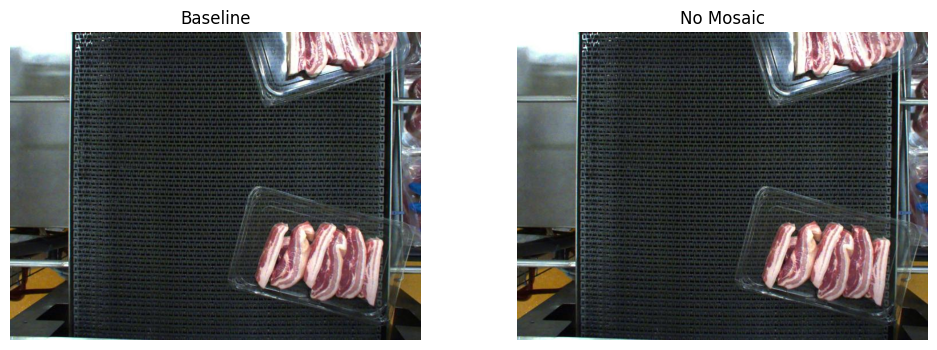

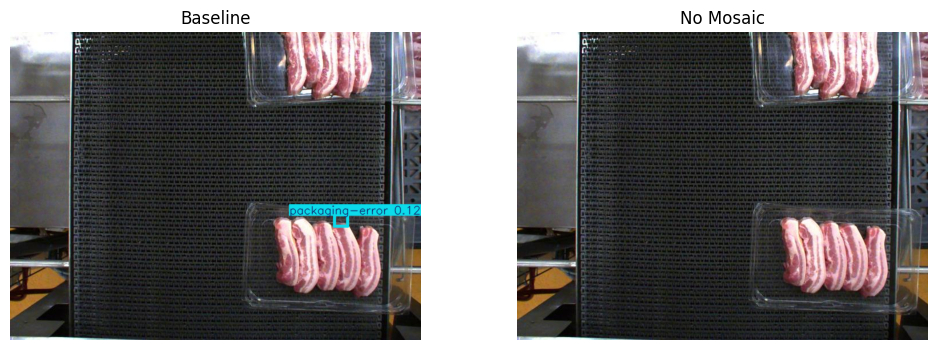

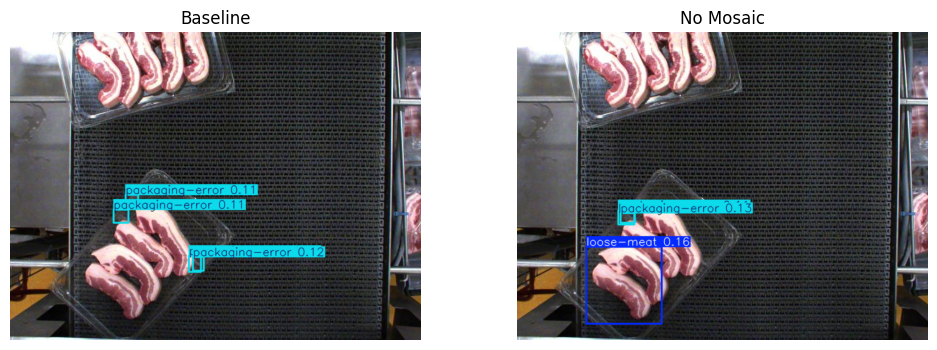

In [18]:
for image_path in no_class_predictions[:3]:

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for ax, (name, model) in zip(axes, [
        ("Baseline", baseline),
        ("No Mosaic", no_mosaic)
    ]):
        result = model.predict(
            str(image_path),
            imgsz=640,
            conf=0.10,
            verbose=False
        )[0]

        ax.imshow(result.plot()[:, :, ::-1])
        ax.set_title(name)
        ax.axis("off")

    plt.show()

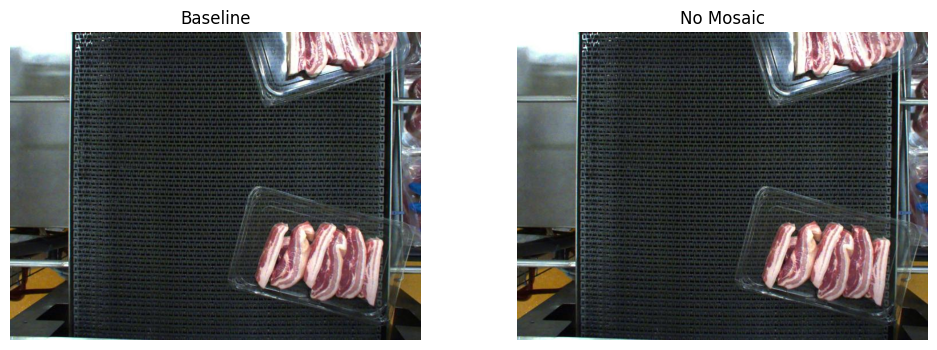

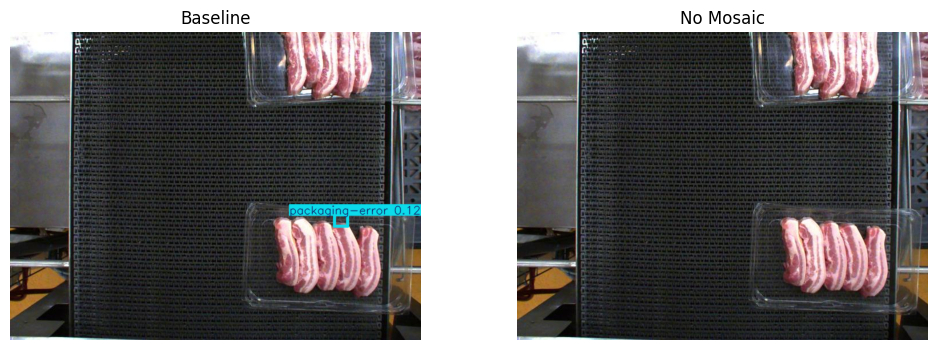

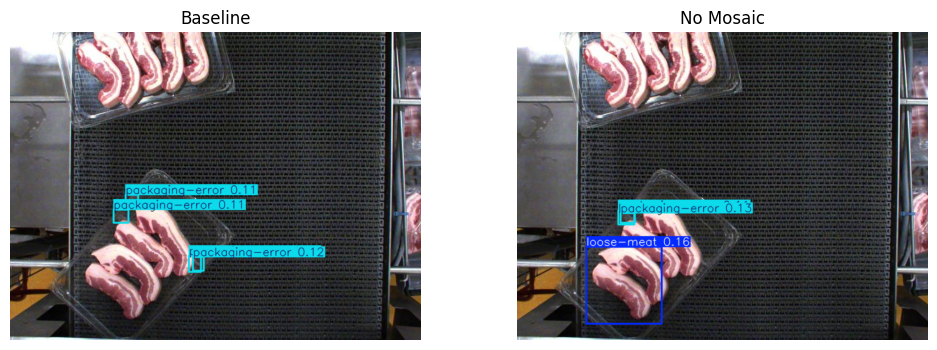

In [19]:
for image_path in no_class_predictions[:3]:

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for ax, (name, model) in zip(axes, [
        ("Baseline", baseline),
        ("No Mosaic", no_mosaic)
    ]):
        result = model.predict(
            str(image_path),
            imgsz=640,
            conf=0.10,
            verbose=False
        )[0]

        ax.imshow(result.plot()[:, :, ::-1])
        ax.set_title(name)
        ax.axis("off")

    plt.show()

In [20]:
test_results = model_640.val(
    data=str(clean / "data.yaml"),
    imgsz=640,
    split="test",
    conf=0.001,
    iou=0.7,
    plots=True,
    project=str(runs),
    name="v1_selected_final_test",
    exist_ok=True
)

print("Test evaluation complete!")

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2427.0±806.6 MB/s, size: 74.0 KB)
val: Scanning /content/pork_rasher_dataset_v1_clean/test/labels... 80 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 80/80 2.1Kit/s 0.0s
val: New cache created: /content/pork_rasher_dataset_v1_clean/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.8it/s 2.8s
                   all         80         99      0.528      0.524      0.544      0.226
            loose-meat          2          3      0.685      0.667      0.775      0.189
       packaging-error         26         37      0.435      0.459      0.376      0.106
          twisted-meat          7          7      0.351      0.239      0.341      0.193
              unsealed         51         52     

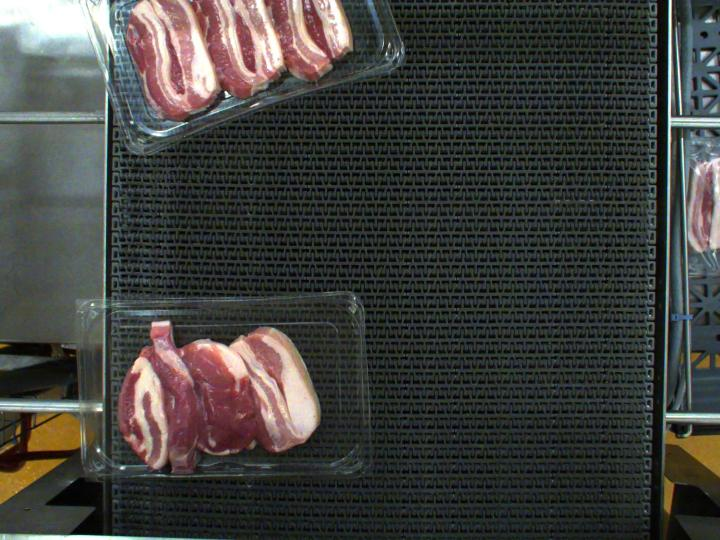

In [21]:
# Demonstrate selected model on a test image
from PIL import Image

image_path = next((clean / "test/images").glob("*.jpg"))

result = model_640.predict(
    source=str(image_path),
    imgsz=640,
    conf=0.201,
    verbose=False
)[0]

display(Image.fromarray(result.plot()[:, :, ::-1]))

In [22]:
def inspect_package(image_path, confidence=0.201):
    """Detect packaging defects using the selected V1 model.

    Args:
        image_path: Path to the image.
        confidence: Minimum detection confidence.

    Returns:
        List of detected defects, confidence scores and bounding boxes.
    """
    result = model_640.predict(
        source=str(image_path), imgsz=640, conf=confidence, verbose=False
    )[0]
    detections = []
    for box in result.boxes:
        detections.append({
            "defect": result.names[int(box.cls.item())],
            "confidence": round(box.conf.item(), 3),
            "box": box.xyxy[0].tolist(),
        })
    return detections

# Example using a test image.
detections = inspect_package(image_path)
print("Detected defects:", detections)

Detected defects: []


In [23]:
def test_inspection_format():
    """Check the inspection output format using real and sample detections."""
    detections = inspect_package(image_path)
    sample = [{
        "defect": "packaging-error",
        "confidence": 0.75,
        "box": [10.0, 20.0, 100.0, 120.0],
    }]

    for items in (detections, sample):
        assert isinstance(items, list)
        for item in items:
            assert item["defect"] in model_640.names.values()
            assert 0 <= item["confidence"] <= 1
            x1, y1, x2, y2 = item["box"]
            assert x1 < x2 and y1 < y2
    print(f"Inspection output checked: {len(detections)} detections in sample image.")


test_inspection_format()

Inspection output checked: 0 detections in sample image.


## Recorded Test Results
The selected no-mosaic model achieved **52.8% precision**, **52.4% recall**, **54.4% mAP50** and **22.6% mAP50–95** on the V1 test set (80 images, 99 labelled defect instances; confidence threshold 0.001).